**Trabalho Prático 2 - State Farm Distracted Driver Detection**

Alunos: um colega e Pedro Vieira


Descrição:
- Dataset de imagens 2D tiradas com uma câmera
- Imagens de motoristas dirigindo
- Avaliar se o motorista está:
  - c0: Condução normal
  - c1: Enviando mensagem – mão direita
  - c2: Falando ao telefone – mão direita
  - c3: Enviando mensagem – mão esquerda
  - c4: Falando ao telefone – mão esquerda
  - c5: Mexendo no rádio
  - c6: Bebendo
  - c7: Buscando algo atrás
  - c8: Cabelo e maquiagem
  - c9: Conversando com o passageiro

- Métrica de erro (multi-class logarithmic loss):


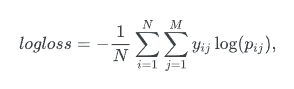

## **Dados da Competição**

In [1]:
# Instalação das dependências
!pip install matplotlib pandas pillow torch torchvision

In [1]:
# Imports necessários

import random
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms

In [2]:
# Variáveis úteis

# Pegando o DataFrame
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

# Pegando o DataFrame
df = pd.read_csv('driver_imgs_list.csv')
print(df.head())

# Device usando GPU se possível (tratado de forma segura caso não haja GPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device_name = torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU'
print(f'Usando device: {device}, hardware detectada: {device_name}')

# Classe para usar no PyTorch
class DriverDataset(Dataset):
    def __init__(self, df, img_dir, transform=None):
        self.df = df
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        classname = row['classname']   # ex: 'c0'
        img_name = row['img']          # ex: 'img_44733.jpg'
        img_path = os.path.join(self.img_dir, classname, img_name)
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        label = int(classname[1:])     # converte 'c0' -> 0
        return image, label

class TestDataset(Dataset):
    def __init__(self, img_dir, transform=None):
        self.img_dir = img_dir
        # Lista todos os arquivos .jpg dentro da pasta de testes
        self.img_names = [f for f in os.listdir(img_dir) if f.endswith('.jpg')]
        self.transform = transform

    def __len__(self):
        return len(self.img_names)

    def __getitem__(self, idx):
        img_name = self.img_names[idx]
        img_path = os.path.join(self.img_dir, img_name)
        image = Image.open(img_path).convert('RGB')
        
        if self.transform:
            image = self.transform(image)
            
        return image, img_name
        
# Dicionário de equivalência da classe
class_dict = {
    'c0': 'normal driving',
    'c1': 'texting - right',
    'c2': 'talking on the phone - right',
    'c3': 'texting - left',
    'c4': 'talking on the phone - left',
    'c5': 'operating the radio',
    'c6': 'drinking',
    'c7': 'reaching behind',
    'c8': 'hair and makeup',
    'c9': 'talking to passenger'
}

  subject classname            img
0    p002        c0  img_44733.jpg
1    p002        c0  img_72999.jpg
2    p002        c0  img_25094.jpg
3    p002        c0  img_69092.jpg
4    p002        c0  img_92629.jpg
Usando device: cuda, hardware detectada: NVIDIA GeForce RTX 2060 SUPER


In [13]:
# Funções úteis

def denormalize(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    
    # Move para a CPU para processar a imagem
    tensor = tensor.cpu()
    tensor = tensor * std + mean
    tensor = torch.clamp(tensor, 0, 1)
    return tensor.permute(1, 2, 0).numpy()

# Função para obter a descrição textual a partir da classe c0, c1...
def get_class_desc(label_idx):
    class_key = f'c{label_idx}'
    return class_dict.get(class_key, class_key)

def plot_saliency_map(model, image_tensor, true_label, device):
    model.eval()
    model.zero_grad()
    
    input_image = image_tensor.clone().unsqueeze(0).to(device)
    input_image.requires_grad_()
    
    output = model(input_image)
    score, pred_idx = torch.max(output, 1)
    score.backward()
    saliency, _ = torch.max(input_image.grad.data.abs(), dim=1)
    saliency = saliency[0].cpu().numpy()
    
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    img_original = denormalize(image_tensor)
    
    axes[0].imshow(img_original)
    axes[0].set_title(f"Original (Real: {get_class_desc(true_label)})")
    axes[0].axis('off')
    
    im = axes[1].imshow(saliency, cmap='hot')
    axes[1].set_title(f"Mapa de Saliência\n(Previsão: {get_class_desc(pred_idx.item())})")
    axes[1].axis('off')
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
    
    plt.tight_layout()
    plt.show()

def plot_saliency_per_class(model, dataset, device):
    model.eval()
    
    # 1. Busca automática: Encontra a primeira imagem de cada classe (0 a 9)
    samples_per_class = {}
    for idx in range(len(dataset)):
        img, label = dataset[idx]
        if label not in samples_per_class:
            samples_per_class[label] = img
        if len(samples_per_class) == 10:
            break
            
    # 2. Configura a grade de exibição (5 linhas, 4 colunas)
    # Cada linha terá: [Original_Classe_A, Saliencia_Classe_A, Original_Classe_B, Saliencia_Classe_B]
    fig, axes = plt.subplots(5, 4, figsize=(18, 22))
    
    for class_idx in range(10):
        img_tensor = samples_per_class[class_idx]
        
        # Calcula o mapa de saliência para este exemplo
        model.zero_grad()
        input_image = img_tensor.clone().unsqueeze(0).to(device)
        input_image.requires_grad_()
        
        output = model(input_image)
        score, pred_idx = torch.max(output, 1)
        score.backward()
        
        saliency, _ = torch.max(input_image.grad.data.abs(), dim=1)
        saliency_np = saliency[0].cpu().numpy()
        
        # Define os índices da linha e coluna na grade
        row = class_idx // 2
        col_orig = (class_idx % 2) * 2
        col_sal = col_orig + 1
        
        # --- Plot da Imagem Original ---
        ax_orig = axes[row, col_orig]
        ax_orig.imshow(denormalize(img_tensor))
        ax_orig.set_title(f"Real: {get_class_desc(class_idx)}", fontsize=10, fontweight='bold')
        ax_orig.axis('off')
        
        # --- Plot do Mapa de Saliência ---
        ax_sal = axes[row, col_sal]
        im = ax_sal.imshow(saliency_np, cmap='hot')
        ax_sal.set_title(f"Saliência (Previsto: {get_class_desc(pred_idx.item())})", 
                         fontsize=10, color='blue' if pred_idx.item() == class_idx else 'red')
        ax_sal.axis('off')
        
    plt.suptitle("Análise de Saliência por Classe - Onde o Modelo Foca?", fontsize=16, fontweight='bold', y=0.99)
    plt.tight_layout()
    plt.show()

def denormalize_safe(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    
    # Trabalha com uma cópia isolada para evitar corrupção de memória
    temp = tensor.cpu().clone()
    temp = temp * std + mean
    temp = torch.clamp(temp, 0, 1)
    return temp.permute(1, 2, 0).numpy()

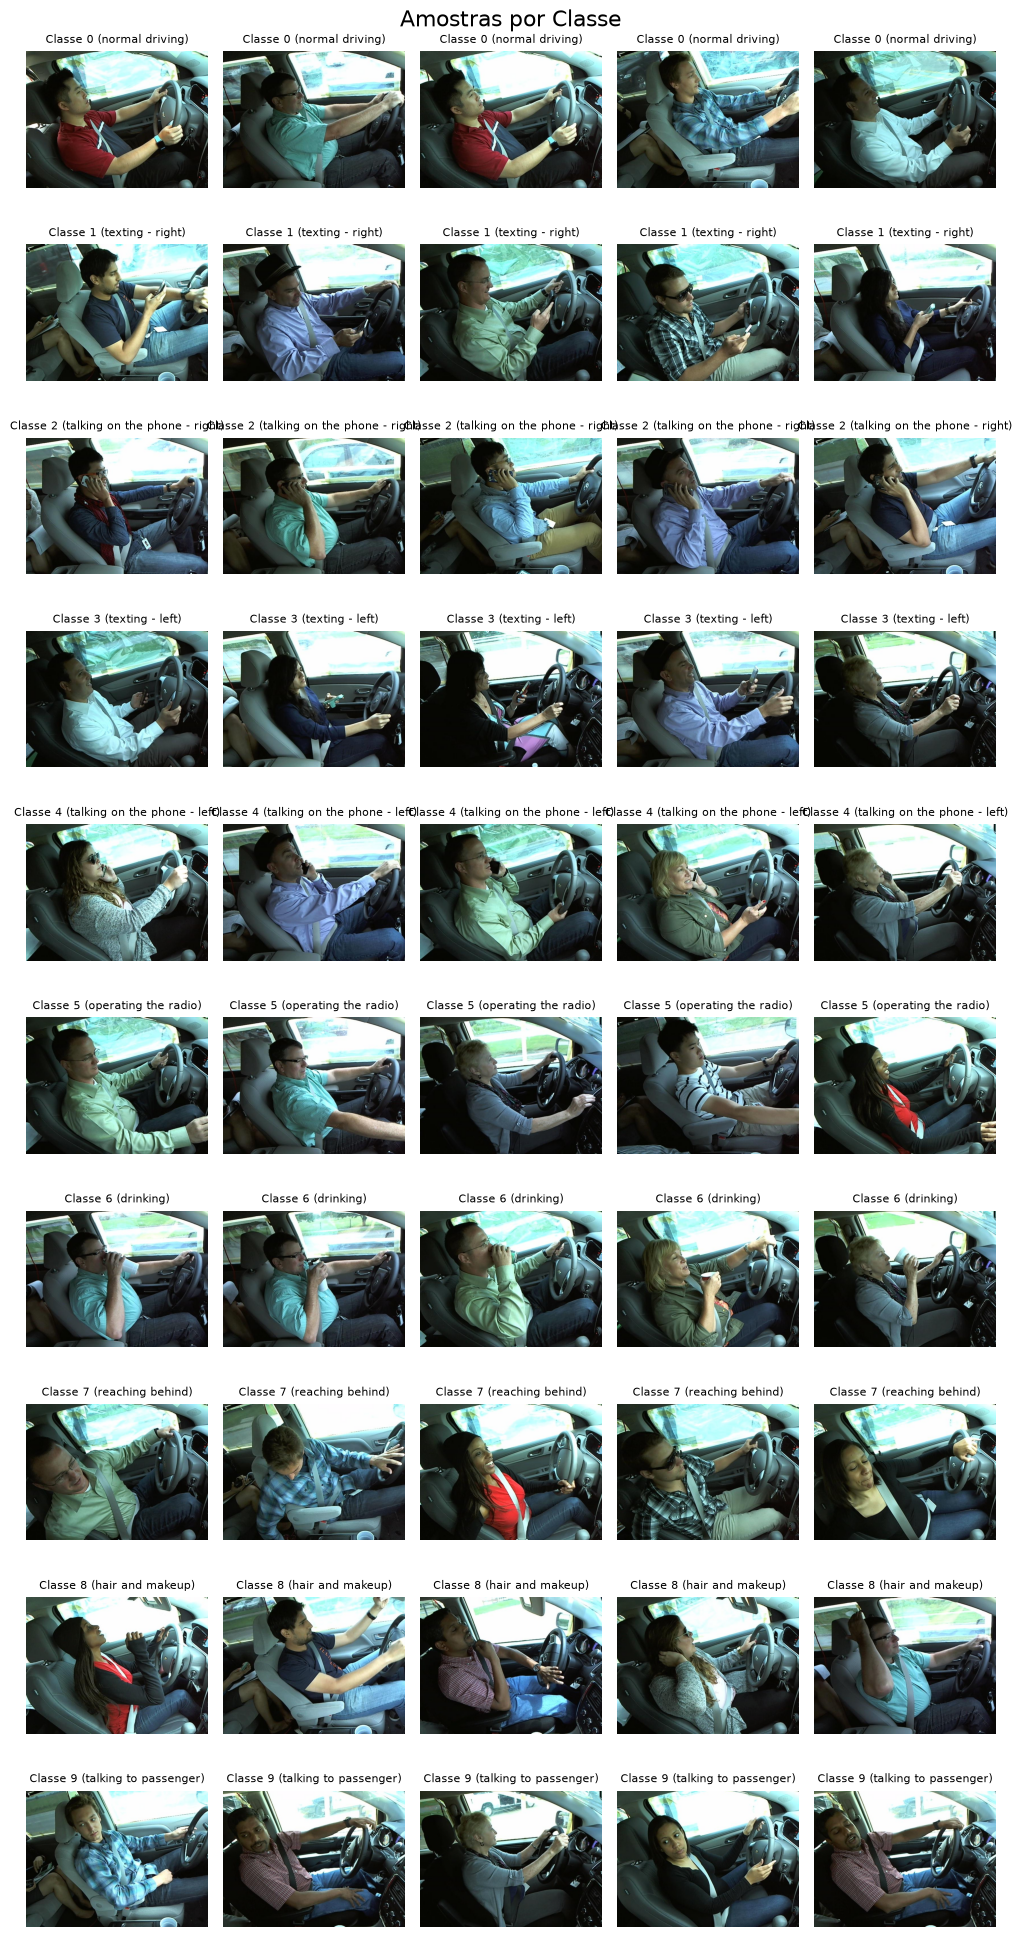

Classe 0 (normal driving): img_74437.jpg, img_65491.jpg, img_13584.jpg, img_19505.jpg, img_96123.jpg
Classe 1 (texting - right): img_41191.jpg, img_32854.jpg, img_80545.jpg, img_3196.jpg, img_56821.jpg
Classe 2 (talking on the phone - right): img_34191.jpg, img_21755.jpg, img_85485.jpg, img_88164.jpg, img_86222.jpg
Classe 3 (texting - left): img_48129.jpg, img_71374.jpg, img_39363.jpg, img_94562.jpg, img_55979.jpg
Classe 4 (talking on the phone - left): img_22127.jpg, img_8253.jpg, img_26033.jpg, img_92684.jpg, img_32554.jpg
Classe 5 (operating the radio): img_83646.jpg, img_51890.jpg, img_58979.jpg, img_66632.jpg, img_64216.jpg
Classe 6 (drinking): img_32246.jpg, img_86108.jpg, img_85980.jpg, img_58904.jpg, img_87868.jpg
Classe 7 (reaching behind): img_59228.jpg, img_67010.jpg, img_34986.jpg, img_23309.jpg, img_23616.jpg
Classe 8 (hair and makeup): img_100821.jpg, img_71204.jpg, img_63830.jpg, img_25156.jpg, img_21790.jpg
Classe 9 (talking to passenger): img_32957.jpg, img_80387.jpg, 

In [5]:
# 5 Amostras de cada instância

n_samples = 5
samples_per_class = {}

for classe in range(10):
    class_df = df[df['classname'] == f"c{classe}"]    
    selected = class_df.sample(n=min(n_samples, len(class_df)), random_state=42)
    samples_per_class[classe] = selected['img'].tolist()

fig, axes = plt.subplots(10, n_samples, figsize=(n_samples*2, 20), squeeze=False)
fig.suptitle('Amostras por Classe', fontsize=16)

for i, classe in enumerate(range(10)):
    for j, img_name in enumerate(samples_per_class[classe]):
        img_path = os.path.join('imgs', 'train', f'c{classe}', img_name)
        try:
            img = Image.open(img_path)
            axes[i, j].imshow(img)
            axes[i, j].axis('off')
            axes[i, j].set_title(f'Classe {classe} ({class_dict[f'c{classe}']})', fontsize=8)
        except FileNotFoundError:
            axes[i, j].text(0.5, 0.5, 'Imagem não encontrada', ha='center')
            axes[i, j].axis('off')
        except Exception as e:
            axes[i, j].text(0.5, 0.5, f'Erro: {e}', ha='center')
            axes[i, j].axis('off')

plt.tight_layout()
plt.show()

for classe, imgs in samples_per_class.items():
    print(f'Classe {classe} ({class_dict[f'c{classe}']}): {", ".join(imgs)}')

In [6]:
# Quantas pessoas (subjects) estão no DataFrame
print(np.sort(df['subject'].unique()).size, ' pessoas:\n')
print(np.sort(df['subject'].unique()))

26  pessoas:

['p002' 'p012' 'p014' 'p015' 'p016' 'p021' 'p022' 'p024' 'p026' 'p035'
 'p039' 'p041' 'p042' 'p045' 'p047' 'p049' 'p050' 'p051' 'p052' 'p056'
 'p061' 'p064' 'p066' 'p072' 'p075' 'p081']


## Baseline (CNN simples)

In [7]:
# Embaralha a lista de motoristas
subjects = list(df['subject'].unique())
random.seed(42)
random.shuffle(subjects)

# 80% dos motoristas para treino, 20% para validação
split_idx = int(len(subjects) * 0.8)
train_subjects = subjects[:split_idx]
val_subjects = subjects[split_idx:]

df_train = df[df['subject'].isin(train_subjects)].reset_index(drop=True)
df_val = df[df['subject'].isin(val_subjects)].reset_index(drop=True)

print(f"Motoristas no Treino: {len(train_subjects)} | Motoristas na Validação: {len(val_subjects)}")

# Tranformações nos DataFrames:

# Valores do ImageNet
# Média: [0.485, 0.456, 0.406]
# StdDev: [0.229, 0.224, 0.225]
transform_train = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

transform_val = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Datasets
train_dataset = DriverDataset(df_train, img_dir='imgs/train', transform=transform_train)
val_dataset = DriverDataset(df_val, img_dir='imgs/train', transform=transform_val)

# DataLoaders
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

print(f'Treino: {len(train_dataset)} imagens, Validação: {len(val_dataset)} imagens')

Motoristas no Treino: 20 | Motoristas na Validação: 6
Treino: 16773 imagens, Validação: 5651 imagens


In [23]:
# CNN simples do baseline

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(SimpleCNN, self).__init__()
        # Bloco 1
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool1 = nn.MaxPool2d(2, 2)  # 128 -> 64

        # Bloco 2
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.pool2 = nn.MaxPool2d(2, 2)  # 64 -> 32

        # Bloco 3
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.pool3 = nn.MaxPool2d(2, 2)  # 32 -> 16

        # Bloco 4
        self.conv4 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(256)
        self.pool4 = nn.MaxPool2d(2, 2)  # 16 -> 8

        # Fully connected
        self.fc1 = nn.Linear(256 * 8 * 8, 256)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool1(self.relu(self.bn1(self.conv1(x))))  # (batch, 32, 64, 64)
        x = self.pool2(self.relu(self.bn2(self.conv2(x))))  # (batch, 64, 32, 32)
        x = self.pool3(self.relu(self.bn3(self.conv3(x))))  # (batch, 128, 16, 16)
        x = self.pool4(self.relu(self.bn4(self.conv4(x))))  # (batch, 256, 8, 8)
        x = x.view(x.size(0), -1)                           # flatten
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)                                     # logits (sem softmax)
        return x

In [9]:
# Modelo baseline
model = SimpleCNN(num_classes=10).to(device)

# Função de perda
criterion = nn.CrossEntropyLoss()

# Otimizador Adam
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Configurações do treinamento
num_epochs = 10 
best_val_loss = float('inf')
print_every = 50  # Frequência dos prints parciais (a cada 50 lotes)

print("Iniciando o treinamento...")

# Listas para guardar o histórico e plotar gráficos depois
history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': []
}

for epoch in range(num_epochs):
    print(f"\n ÉPOCA {epoch+1}/{num_epochs} ")
    
    # Treino
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    print("  [Treino] Processando lotes:")
    for batch_idx, (images, labels) in enumerate(train_loader):
        images, labels = images.to(device), labels.to(device)
        
        # Zera os gradientes acumulados
        optimizer.zero_grad()
        
        # Forward propagation
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # Backward propagation
        loss.backward()
        
        # Atualiza os pesos da rede
        optimizer.step()
        
        # Acumula as métricas de treino
        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        
        # Print de feedback parcial durante a época de treino
        if (batch_idx + 1) % print_every == 0 or (batch_idx + 1) == len(train_loader):
            partial_loss = running_loss / total_train
            partial_acc = (correct_train / total_train) * 100
            print(f"    Lote [{batch_idx+1}/{len(train_loader)}] -> "
                  f"Loss parcial: {partial_loss:.4f} | Acc parcial: {partial_acc:.2f}%")
        
    epoch_train_loss = running_loss / len(train_loader.dataset)
    epoch_train_acc = correct_train / total_train
    
    # Validação
    model.eval()
    running_val_loss = 0.0
    correct_val = 0
    total_val = 0
    
    print("  [Validação] Processando lotes:")
    # Desativa o cálculo de gradientes para economizar memória e processamento
    with torch.no_grad():
        for batch_idx, (images, labels) in enumerate(val_loader):
            images, labels = images.to(device), labels.to(device)
            
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            # Acumula as métricas de validação
            running_val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()
            
            # Print de feedback parcial durante a validação
            if (batch_idx + 1) % print_every == 0 or (batch_idx + 1) == len(val_loader):
                partial_val_loss = running_val_loss / total_val
                partial_val_acc = (correct_val / total_val) * 100
                print(f"    Lote [{batch_idx+1}/{len(val_loader)}] -> "
                      f"Loss parcial: {partial_val_loss:.4f} | Acc parcial: {partial_val_acc:.2f}%")
            
    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    epoch_val_acc = correct_val / total_val
    
    # Salva o histórico
    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(epoch_train_acc)
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(epoch_val_acc)
    
    # Exibe o resumo consolidado da época
    print(f"\n--- FIM DA ÉPOCA {epoch+1} | "
          f"Loss Treino: {epoch_train_loss:.4f} - Acc Treino: {epoch_train_acc*100:.2f}% | "
          f"Loss Val: {epoch_val_loss:.4f} - Acc Val: {epoch_val_acc*100:.2f}%")
    
    # Salva o melhor modelo com base na perda de validação
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), 'best_baseline_model.pth')
        print(f"--> [SALVO] Novo melhor modelo gravado! Loss Val: {best_val_loss:.4f}")

print("\nTreinamento concluído!")

Iniciando o treinamento...

 ÉPOCA 1/10 
  [Treino] Processando lotes:
    Lote [50/263] -> Loss parcial: 2.7237 | Acc parcial: 17.94%
    Lote [100/263] -> Loss parcial: 2.2791 | Acc parcial: 24.45%
    Lote [150/263] -> Loss parcial: 2.0334 | Acc parcial: 29.79%
    Lote [200/263] -> Loss parcial: 1.8644 | Acc parcial: 34.52%
    Lote [250/263] -> Loss parcial: 1.7321 | Acc parcial: 38.32%
    Lote [263/263] -> Loss parcial: 1.7063 | Acc parcial: 39.08%
  [Validação] Processando lotes:
    Lote [50/89] -> Loss parcial: 1.8204 | Acc parcial: 51.69%
    Lote [89/89] -> Loss parcial: 1.5323 | Acc parcial: 53.71%

--- FIM DA ÉPOCA 1 | Loss Treino: 1.7063 - Acc Treino: 39.08% | Loss Val: 1.5323 - Acc Val: 53.71%
--> [SALVO] Novo melhor modelo gravado! Loss Val: 1.5323

 ÉPOCA 2/10 
  [Treino] Processando lotes:
    Lote [50/263] -> Loss parcial: 1.0226 | Acc parcial: 60.72%
    Lote [100/263] -> Loss parcial: 0.9735 | Acc parcial: 63.11%
    Lote [150/263] -> Loss parcial: 0.9583 | Acc pa

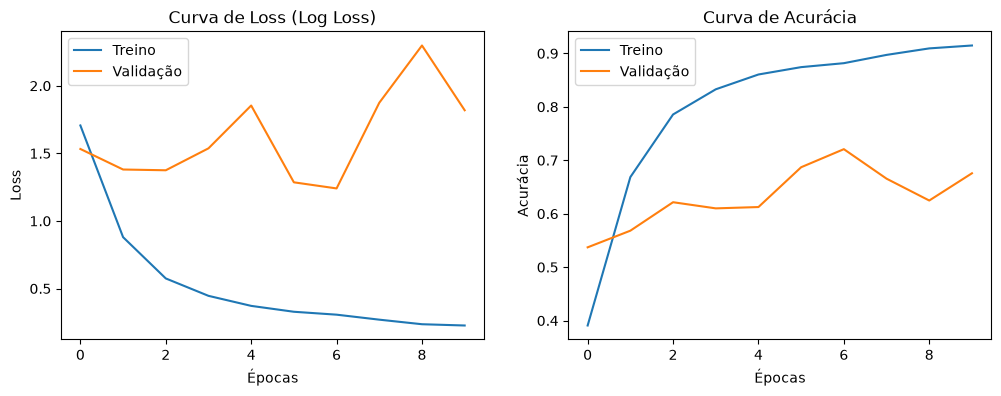

In [12]:
plt.figure(figsize=(12, 4))

# Gráfico de Perda (Loss)
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Treino')
plt.plot(history['val_loss'], label='Validação')
plt.title('Curva de Loss (Log Loss)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()

# Gráfico de Acurácia
plt.subplot(1, 2, 2)
plt.plot(history['train_acc'], label='Treino')
plt.plot(history['val_acc'], label='Validação')
plt.title('Curva de Acurácia')
plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.legend()

plt.show()

In [12]:
# Listas para guardar nossas amostras
correct_samples = []
incorrect_samples = []

# Conjuntos para garantir que pegaremos classes distintas
classes_corretas_vistas = set()
classes_incorretas_vistas = set()

# Garante modo de avaliação
model.eval()  

print("Analisando predições no conjunto de validação com diversidade de classes...")

with torch.no_grad():
    for images, labels in val_loader:
        images_dev = images.to(device)
        outputs = model(images_dev)
        _, preds = torch.max(outputs, 1)
        
        preds = preds.cpu()
        labels = labels.cpu()
        
        for i in range(images.size(0)):
            # Cria uma cópia independente na memória
            img = images[i].clone() 
            
            true_label = labels[i].item()
            pred_label = preds[i].item()
            
            # 1. Se acertou: só adiciona se ainda não tivermos essa classe salva nos acertos
            if true_label == pred_label:
                if len(correct_samples) < 5 and true_label not in classes_corretas_vistas:
                    correct_samples.append((img, true_label, pred_label))
                    classes_corretas_vistas.add(true_label)
                    
            # 2. Se errou: só adiciona se ainda não tivermos essa classe salva nos erros
            else:
                if len(incorrect_samples) < 5 and true_label not in classes_incorretas_vistas:
                    incorrect_samples.append((img, true_label, pred_label))
                    classes_incorretas_vistas.add(true_label)
                    
        # Interrompe se já conseguimos 5 amostras variadas de cada tipo
        if len(correct_samples) >= 5 and len(incorrect_samples) >= 5:
            break

# --- Garante que a função denormalize não faça modificações in-place ---
def denormalize_safe(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    
    # Trabalha com uma cópia isolada para evitar corrupção de memória
    temp = tensor.cpu().clone()
    temp = temp * std + mean
    temp = torch.clamp(temp, 0, 1)
    return temp.permute(1, 2, 0).numpy()

# --- Renderização do Gráfico ---
fig, axes = plt.subplots(2, 5, figsize=(18, 8))

# Linha 0: Acertos do Modelo (Classes Variadas)
for idx, (img, true_l, pred_l) in enumerate(correct_samples):
    ax = axes[0, idx]
    ax.imshow(denormalize_safe(img))
    ax.axis('off')
    ax.set_title(f"Real: {get_class_desc(true_l)}\nPrevisto: {get_class_desc(pred_l)}", 
                 color='green', fontsize=9, fontweight='bold')
    if idx == 0:
        ax.text(-35, 64, "ACERTOS", rotation=90, va='center', ha='center', fontsize=12, fontweight='bold', color='green')

# Linha 1: Erros do Modelo (Classes Variadas)
for idx, (img, true_l, pred_l) in enumerate(incorrect_samples):
    ax = axes[1, idx]
    ax.imshow(denormalize_safe(img))
    ax.axis('off')
    ax.set_title(f"Real: {get_class_desc(true_l)}\nPrevisto: {get_class_desc(pred_l)}", 
                 color='red', fontsize=9, fontweight='bold')
    if idx == 0:
        ax.text(-35, 64, "ERROS", rotation=90, va='center', ha='center', fontsize=12, fontweight='bold', color='red')

plt.suptitle("Amostras Qualitativas de Acertos e Erros (Classes Diversificadas)", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

NameError: name 'model' is not defined

C:\Users\um colega\AppData\Local\Temp\ipykernel_11600\2684104594.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_baseline_model.pt

Melhor modelo do baseline carregado com sucesso!


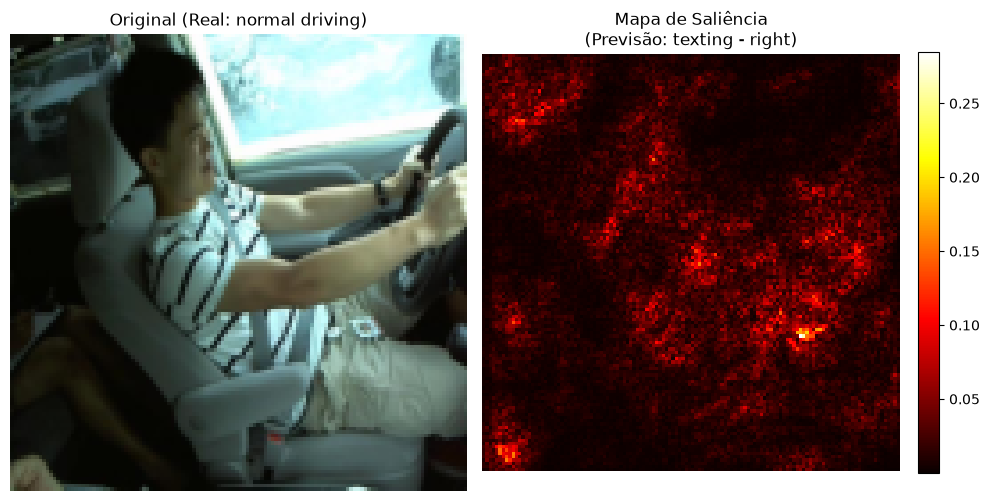

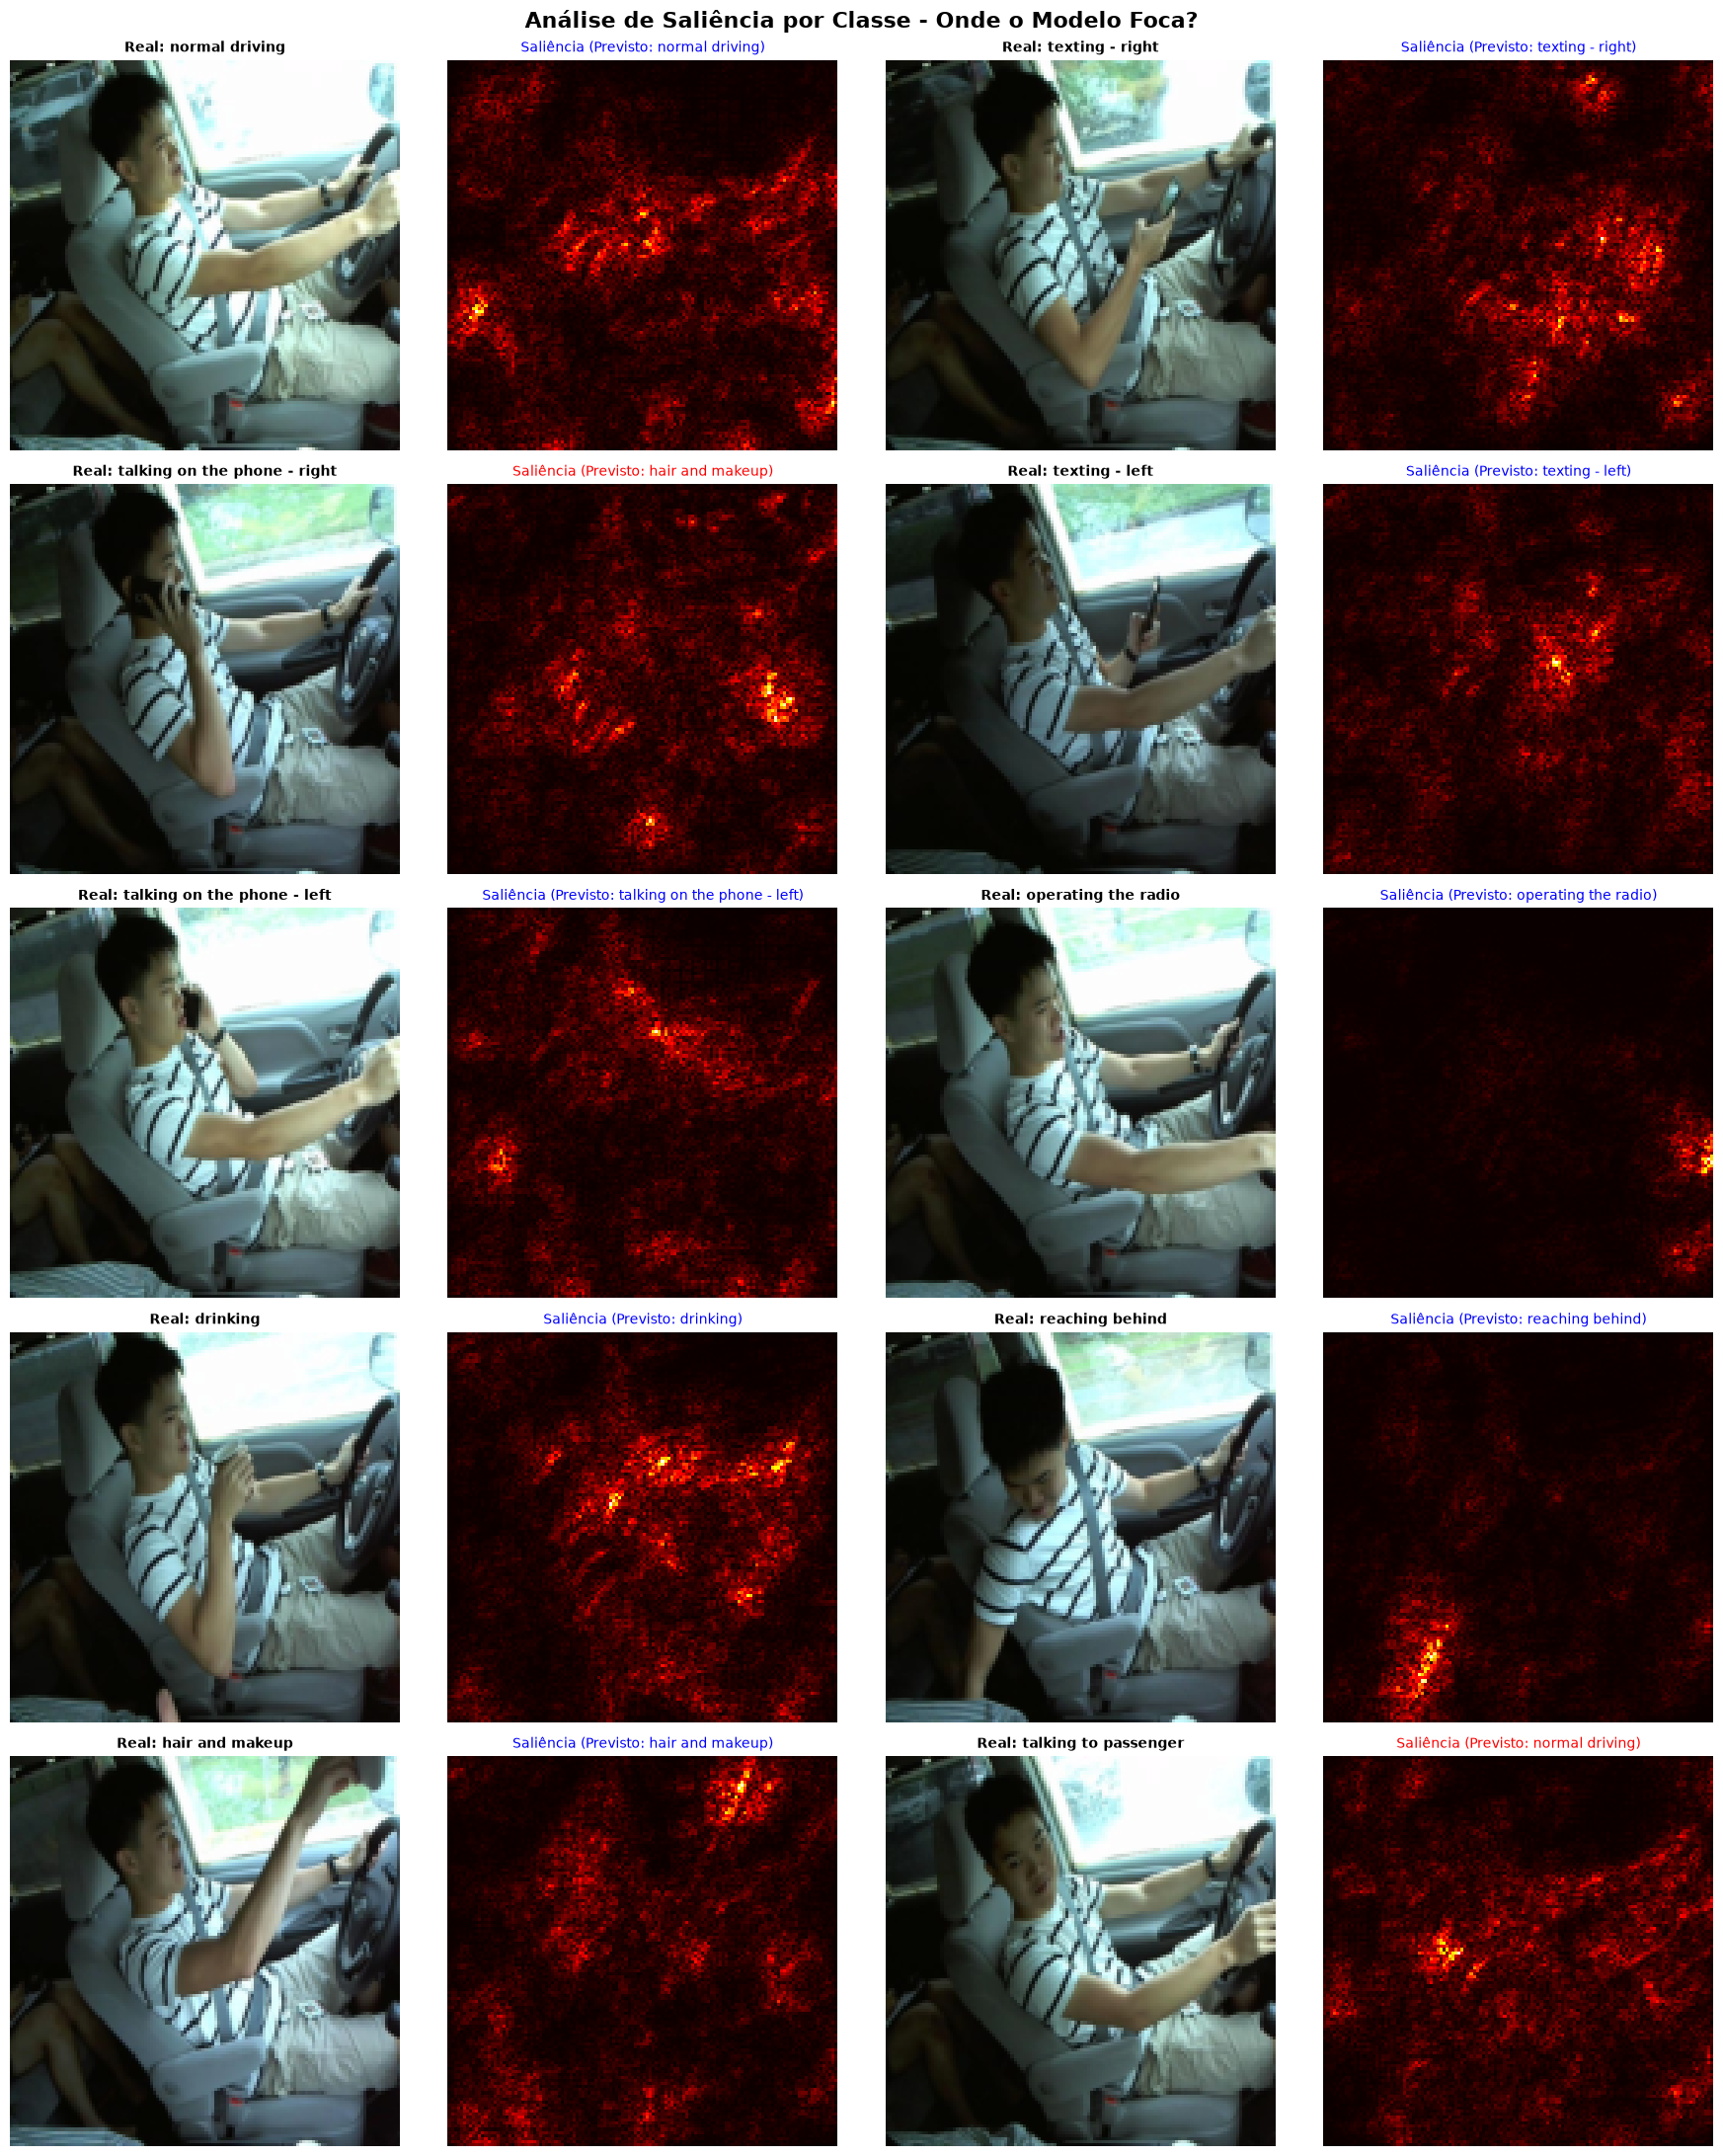

In [14]:

model.load_state_dict(torch.load('best_baseline_model.pth', map_location=device))
model.eval()
print("Melhor modelo do baseline carregado com sucesso!")

# Pega a imagem de índice 12 (por exemplo) do conjunto de validação
imagem_teste, rotulo_teste = val_dataset[12]

# Mapa de saliência para a imagem 12
plot_saliency_map(model, imagem_teste, rotulo_teste, device)

# Mapa de saliência por classe
plot_saliency_per_class(model, val_dataset, device)

In [9]:
test_dir = 'imgs/test' 

test_dataset = TestDataset(img_dir=test_dir, transform=transform_val)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=0)

print(f"Total de imagens no conjunto de teste: {len(test_dataset)}")

Total de imagens no conjunto de teste: 79726


In [16]:
model.load_state_dict(torch.load('best_baseline_model.pth', map_location=device))
model.eval()

submission_data = []

print("Iniciando a predição para o conjunto de testes...")

with torch.no_grad():
    for batch_idx, (images, filenames) in enumerate(test_loader):
        images = images.to(device)        
        outputs = model(images)
        
        probabilities = torch.softmax(outputs, dim=1)
        
        probabilities = probabilities.cpu().numpy()
        
        for filename, probs in zip(filenames, probabilities):
            row = {'img': filename}
            for i in range(10):
                row[f'c{i}'] = probs[i]
            submission_data.append(row)
            
        if (batch_idx + 1) % 50 == 0 or (batch_idx + 1) == len(test_loader):
            print(f"  Progresso: Lote [{batch_idx+1}/{len(test_loader)}] processado.")

submission_df = pd.DataFrame(submission_data)
cols = ['img'] + [f'c{i}' for i in range(10)]
submission_df = submission_df[cols]
submission_df.to_csv('submission.csv', index=False)

print("\nPredições concluídas!")
print("Arquivo 'submission.csv' gerado com sucesso!")

C:\Users\um colega\AppData\Local\Temp\ipykernel_11600\2785491261.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_baseline_model.pt

Iniciando a predição para o conjunto de testes...
  Progresso: Lote [50/1246] processado.
  Progresso: Lote [100/1246] processado.
  Progresso: Lote [150/1246] processado.
  Progresso: Lote [200/1246] processado.
  Progresso: Lote [250/1246] processado.
  Progresso: Lote [300/1246] processado.
  Progresso: Lote [350/1246] processado.
  Progresso: Lote [400/1246] processado.
  Progresso: Lote [450/1246] processado.
  Progresso: Lote [500/1246] processado.
  Progresso: Lote [550/1246] processado.
  Progresso: Lote [600/1246] processado.
  Progresso: Lote [650/1246] processado.
  Progresso: Lote [700/1246] processado.
  Progresso: Lote [750/1246] processado.
  Progresso: Lote [800/1246] processado.
  Progresso: Lote [850/1246] processado.
  Progresso: Lote [900/1246] processado.
  Progresso: Lote [950/1246] processado.
  Progresso: Lote [1000/1246] processado.
  Progresso: Lote [1050/1246] processado.
  Progresso: Lote [1100/1246] processado.
  Progresso: Lote [1150/1246] processado.
  Pr

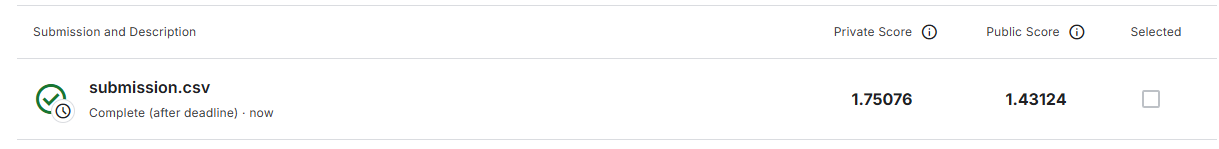

## Solução Própria (Staking de CNN + ResNet-18, RF)

In [23]:
!pip install scikit-learn

  Using cached joblib-1.5.3-py3-none-any.whl.metadata (5.5 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ----------- ---------------------------- 2.4/8.2 MB 14.9 MB/s eta 0:00:01
   ------------------------------ --------- 6.3/8.2 MB 16.7 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 15.4 MB/s  0:00:00
Using cached joblib-1.5.3-py3-none-any.whl (309 kB)
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.3/36.6 MB ? eta -:--:--
   - -------------------------------------- 1.0/36.6 MB 2.1 MB/s eta 0:00:17
   ---- ----------------------------------- 4.5/36.6 MB 7.3 MB/s eta 0:00:05
   -------- ------------------------------- 7.9/36.6 MB 10.1 MB/s eta 0:00:03
   ------------- -------------------------- 12.6/36.6 MB 12.1 MB/s eta 0:00:02
   ----------------- ---------------------- 16.3/36.6 MB 13.1 MB/s e

In [4]:
class ResidualBlock(nn.Module):
    """
    Bloco Residual Customizado para permitir o fluxo direto de gradientes (Skip Connections).
    """
    def __init__(self, in_channels, out_channels, stride=1):
        super(ResidualBlock, self).__init__()
        # Primeira Convolução do Bloco
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        
        # Segunda Convolução do Bloco
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        
        # Atalho (Shortcut) caso as dimensões de canais mudem
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )
            
    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        # Soma a entrada original (Skip Connection)
        out += self.shortcut(x)
        out = self.relu(out)
        return out


class CustomResCNN(nn.Module):
    """
    Nova arquitetura convolucional customizada com Conexões Residuais 
    e Global Average Pooling (GAP) para substituir o baseline.
    """
    def __init__(self, num_classes=10):
        super(CustomResCNN, self).__init__()
        self.in_channels = 32
        
        # Camada de Entrada: 3x128x128 -> 32x128x128
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(32)
        self.relu = nn.ReLU(inplace=True)
        
        # Bloco Residual 1 + Pooling -> 32x64x64
        self.layer1 = self._make_layer(32, stride=1)
        self.pool1 = nn.MaxPool2d(2, 2)
        
        # Bloco Residual 2 + Pooling -> 64x32x32
        self.layer2 = self._make_layer(64, stride=1)
        self.pool2 = nn.MaxPool2d(2, 2)
        
        # Bloco Residual 3 + Pooling -> 128x16x16
        self.layer3 = self._make_layer(128, stride=1)
        self.pool3 = nn.MaxPool2d(2, 2)
        
        # Bloco Residual 4 + Pooling -> 256x8x8
        self.layer4 = self._make_layer(256, stride=1)
        self.pool4 = nn.MaxPool2d(2, 2)
        
        # Global Average Pooling (GAP) em vez de Flatten gigante
        self.gap = nn.AdaptiveAvgPool2d((1, 1)) # Reduz para 256x1x1
        
        # Classificador Linear Simples (Apenas 2.560 parâmetros!)
        self.fc = nn.Linear(256, num_classes)
        
    def _make_layer(self, out_channels, stride):
        layers = []
        layers.append(ResidualBlock(self.in_channels, out_channels, stride))
        self.in_channels = out_channels
        return nn.Sequential(*layers)
        
    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.pool1(self.layer1(out))
        out = self.pool2(self.layer2(out))
        out = self.pool3(self.layer3(out))
        out = self.pool4(self.layer4(out))
        out = self.gap(out)
        out = out.view(out.size(0), -1)
        out = self.fc(out)
        return out

In [10]:
import os
from sklearn.model_selection import GroupKFold
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

# Defina aqui o número total de Folds que você configurou originalmente (ex: 10)
num_folds = 10  
gkf = GroupKFold(n_splits=num_folds)

# Garante a conversão correta dos rótulos para inteiro
df['label'] = df['classname'].str[1:].astype(int)
groups = df['subject'].values

# Inicializa/Zera os arrays globais na memória RAM
oof_preds_cnn = np.zeros((len(df), 10))
oof_preds_res = np.zeros((len(df), 10))

print(f"Iniciando loop do GroupKFold com restauração automática de progresso...")

for fold, (train_idx, val_idx) in enumerate(gkf.split(df, groups=groups)):
    print(f"\n=================== DOBRA {fold+1}/{num_folds} ===================")
    
    # Nomes dos arquivos esperados para esta dobra
    cnn_path = f'custom_model_fold_{fold}.pth'
    resnet_path = f'resnet_model_fold_{fold}.pth'
    
    # Configura os DataFrames e loaders da dobra
    df_fold_train = df.iloc[train_idx].reset_index(drop=True)
    df_fold_val = df.iloc[val_idx].reset_index(drop=True)
    
    train_dataset = DriverDataset(df_fold_train, img_dir='imgs/train', transform=transform_train_adv)
    val_dataset = DriverDataset(df_fold_val, img_dir='imgs/train', transform=transform_val)
    
    val_loader_fold = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=0)
    
    # --- VERIFICAÇÃO DE PROGRESSO SALVO ---
    if os.path.exists(cnn_path) and os.path.exists(resnet_path):
        # CASO JÁ EXISTA: Apenas carrega os modelos e reconstrói as probabilidades OOF na RAM
        print(f"  [RESTAURAÇÃO] Dobra {fold+1} já treinada localmente.")
        print(f"  -> Carregando pesos salvos e gerando probabilidades OOF...")
        
        # Carrega CustomResCNN salva
        model_cnn = CustomResCNN(num_classes=10).to(device)
        model_cnn.load_state_dict(torch.load(cnn_path, map_location=device))
        model_cnn.eval()
        
        # Carrega ResNet18 salva
        model_res = resnet18()
        model_res.fc = nn.Linear(model_res.fc.in_features, 10)
        model_res.load_state_dict(torch.load(resnet_path, map_location=device))
        model_res.to(device)
        model_res.eval()
        
    else:
        # CASO NÃO EXISTA: Executa o treinamento completo do zero para esta dobra
        print(f"  [TREINO] Dobra {fold+1} não encontrada. Iniciando treinamento...")
        train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=0)
        
        # 1. Treino da CustomResCNN
        print(f"    -> Treinando CustomResCNN para o Fold {fold+1}...")
        model_cnn = CustomResCNN(num_classes=10).to(device)
        criterion_cnn = nn.CrossEntropyLoss()
        optimizer_cnn = optim.Adam(model_cnn.parameters(), lr=0.001)
        
        for epoch in range(5): 
            model_cnn.train()
            for images, labels in train_loader:
                images, labels = images.to(device), labels.to(device)
                optimizer_cnn.zero_grad()
                outputs = model_cnn(images)
                loss = criterion_cnn(outputs, labels)
                loss.backward()
                optimizer_cnn.step()
                
        torch.save(model_cnn.state_dict(), cnn_path)
        
        # 2. Treino da ResNet-18
        print(f"    -> Treinando ResNet-18 para o Fold {fold+1}...")
        model_res = resnet18(weights=ResNet18_Weights.DEFAULT)
        model_res.fc = nn.Linear(model_res.fc.in_features, 10)
        model_res = model_res.to(device)
        
        criterion_res = nn.CrossEntropyLoss()
        optimizer_res = optim.Adam(model_res.parameters(), lr=0.0001)
        
        for epoch in range(4): 
            model_res.train()
            for images, labels in train_loader:
                images, labels = images.to(device), labels.to(device)
                optimizer_res.zero_grad()
                outputs = model_res(images)
                loss = criterion_res(outputs, labels)
                loss.backward()
                optimizer_res.step()
                
        torch.save(model_res.state_dict(), resnet_path)
        
        # Prepara para a validação rápida
        model_cnn.eval()
        model_res.eval()
        print(f"    -> Treinamento da dobra {fold+1} concluído e salvo!")

    # --- 3. EXTRAÇÃO DAS PREDIÇÕES DE VALIDAÇÃO (OOF) ---
    # (Roda tanto para as dobras restauradas quanto para as novas)
    with torch.no_grad():
        current_idx = 0
        for images, _ in val_loader_fold:
            images = images.to(device)
            probs_cnn = torch.softmax(model_cnn(images), dim=1).cpu().numpy()
            probs_res = torch.softmax(model_res(images), dim=1).cpu().numpy()
            
            num_imgs_batch = images.size(0)
            actual_val_indices = val_idx[current_idx : current_idx + num_imgs_batch]
            
            oof_preds_cnn[actual_val_indices] = probs_cnn
            oof_preds_res[actual_val_indices] = probs_res
            current_idx += num_imgs_batch

print("\nProcesso de Validação Cruzada concluído com sucesso!")

# --- 3. TREINAMENTO DO META-CLASSIFICADOR ---
# Concatena as features OOF geradas de forma robusta
X_stack_oof = np.hstack([oof_preds_cnn, oof_preds_res])
y_stack_oof = df['label'].values

# Inicializa e treina o Random Forest
meta_rf_oof = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
meta_rf_oof.fit(X_stack_oof, y_stack_oof)

# Avaliação local do Stacking com Validação Cruzada
val_preds_oof = meta_rf_oof.predict(X_stack_oof)
val_probs_oof = meta_rf_oof.predict_proba(X_stack_oof)

acc_oof = accuracy_score(y_stack_oof, val_preds_oof)
loss_oof = log_loss(y_stack_oof, val_probs_oof)

print("\n=== RESULTADOS FINAIS DO STACKING COM GROUPKFOLD ===")
print(f"Acurácia Geral Out-of-Fold: {acc_oof*100:.2f}%")
print(f"Log Loss Geral Out-of-Fold (Métrica do Kaggle): {loss_oof:.4f}")

# --- 4. GERAÇÃO DA SUBMISSÃO DO KAGGLE (MÉDIA DOS FOLDS) ---

# Carrega todos os modelos treinados nas dobras em listas para usá-los em conjunto
cnns_trained = []
resnets_trained = []

for fold in range(num_folds):
    cnn = CustomResCNN(num_classes=10).to(device)
    cnn.load_state_dict(torch.load(f'custom_model_fold_{fold}.pth', map_location=device))
    cnn.eval()
    cnns_trained.append(cnn)
    
    res = resnet18()
    res.fc = nn.Linear(res.fc.in_features, 10)
    res.load_state_dict(torch.load(f'resnet_model_fold_{fold}.pth', map_location=device))
    res.to(device)
    res.eval()
    resnets_trained.append(res)

test_submission_data = []

print("\nGerando predições finais para o Kaggle usando Stacking com Média dos Folds...")
with torch.no_grad():
    for batch_idx, (images, filenames) in enumerate(test_loader):
        images = images.to(device)
        
        # Listas para guardar as saídas temporárias de cada fold para este lote
        batch_probs_cnn_folds = []
        batch_probs_res_folds = []
        
        # Passa as imagens de teste por todas as dobras
        for fold in range(num_folds):
            probs_cnn = torch.softmax(cnns_trained[fold](images), dim=1).cpu().numpy()
            probs_res = torch.softmax(resnets_trained[fold](images), dim=1).cpu().numpy()
            
            batch_probs_cnn_folds.append(probs_cnn)
            batch_probs_res_folds.append(probs_res)
            
        # Tira a média aritmética das previsões de todas as dobras
        avg_probs_cnn = np.mean(batch_probs_cnn_folds, axis=0)
        avg_probs_res = np.mean(batch_probs_res_folds, axis=0)
        
        # Monta o vetor de 20 features mesclando as médias
        batch_features = [np.concatenate([p_cnn, p_res]) for p_cnn, p_res in zip(avg_probs_cnn, avg_probs_res)]
        
        # O Random Forest (corrigido para meta_rf_oof!) gera as probabilidades finais
        final_probs = meta_rf_oof.predict_proba(batch_features)
        
        for filename, probs in zip(filenames, final_probs):
            row = {'img': filename}
            for i in range(10):
                row[f'c{i}'] = probs[i]
            test_submission_data.append(row)
            
        if (batch_idx + 1) % 50 == 0 or (batch_idx + 1) == len(test_loader):
            print(f"  Progresso: Lote [{batch_idx+1}/{len(test_loader)}] processado.")

# Salva o arquivo final de submissão do Stacking
submission_stack_df = pd.DataFrame(test_submission_data)
cols = ['img'] + [f'c{i}' for i in range(10)]
submission_stack_df = submission_stack_df[cols]
submission_stack_df.to_csv('submission_stacking.csv', index=False)

print("\nSubmissão do Stacking gerada com sucesso! Arquivo salvo como: 'submission_stacking.csv'")

Iniciando loop do GroupKFold com restauração automática de progresso...

=================== DOBRA 1/10 ===================
  [RESTAURAÇÃO] Dobra 1 já treinada localmente.
  -> Carregando pesos salvos e gerando probabilidades OOF...


C:\Users\um colega\AppData\Local\Temp\ipykernel_15884\881917741.py:48: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_cnn.load_state_dict(torch.load(cnn_path, map_locat


=================== DOBRA 2/10 ===================
  [RESTAURAÇÃO] Dobra 2 já treinada localmente.
  -> Carregando pesos salvos e gerando probabilidades OOF...

=================== DOBRA 3/10 ===================
  [RESTAURAÇÃO] Dobra 3 já treinada localmente.
  -> Carregando pesos salvos e gerando probabilidades OOF...

=================== DOBRA 4/10 ===================
  [RESTAURAÇÃO] Dobra 4 já treinada localmente.
  -> Carregando pesos salvos e gerando probabilidades OOF...

=================== DOBRA 5/10 ===================
  [RESTAURAÇÃO] Dobra 5 já treinada localmente.
  -> Carregando pesos salvos e gerando probabilidades OOF...

=================== DOBRA 6/10 ===================
  [RESTAURAÇÃO] Dobra 6 já treinada localmente.
  -> Carregando pesos salvos e gerando probabilidades OOF...

=================== DOBRA 7/10 ===================
  [RESTAURAÇÃO] Dobra 7 já treinada localmente.
  -> Carregando pesos salvos e gerando probabilidades OOF...

=================== DOBRA 8/10 ==

C:\Users\um colega\AppData\Local\Temp\ipykernel_15884\881917741.py:153: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  cnn.load_state_dict(torch.load(f'custom_model_fold_{fol


Gerando predições finais para o Kaggle usando Stacking com Média dos Folds...
  Progresso: Lote [50/1246] processado.
  Progresso: Lote [100/1246] processado.
  Progresso: Lote [150/1246] processado.
  Progresso: Lote [200/1246] processado.
  Progresso: Lote [250/1246] processado.
  Progresso: Lote [300/1246] processado.
  Progresso: Lote [350/1246] processado.
  Progresso: Lote [400/1246] processado.
  Progresso: Lote [450/1246] processado.
  Progresso: Lote [500/1246] processado.
  Progresso: Lote [550/1246] processado.
  Progresso: Lote [600/1246] processado.
  Progresso: Lote [650/1246] processado.
  Progresso: Lote [700/1246] processado.
  Progresso: Lote [750/1246] processado.
  Progresso: Lote [800/1246] processado.
  Progresso: Lote [850/1246] processado.
  Progresso: Lote [900/1246] processado.
  Progresso: Lote [950/1246] processado.
  Progresso: Lote [1000/1246] processado.
  Progresso: Lote [1050/1246] processado.
  Progresso: Lote [1100/1246] processado.
  Progresso: Lote

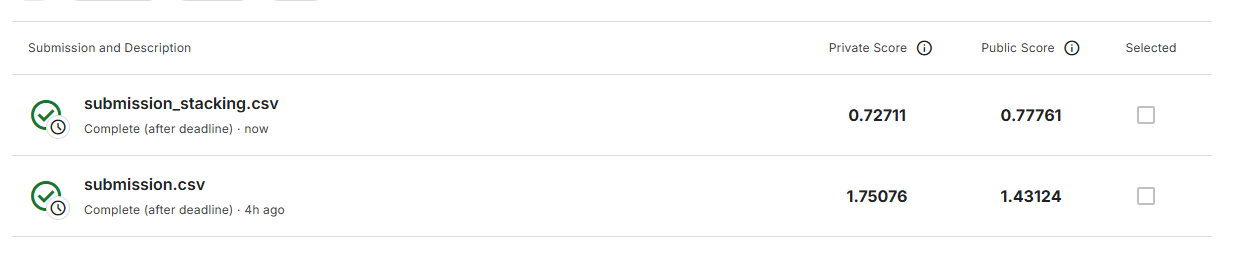

C:\Users\um colega\AppData\Local\Temp\ipykernel_15884\2386840193.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  cnn.load_state_dict(torch.load(f'custom_model_fold_{fold

Analisando predições do Stacking Final (Média dos Folds + Random Forest) na validação...


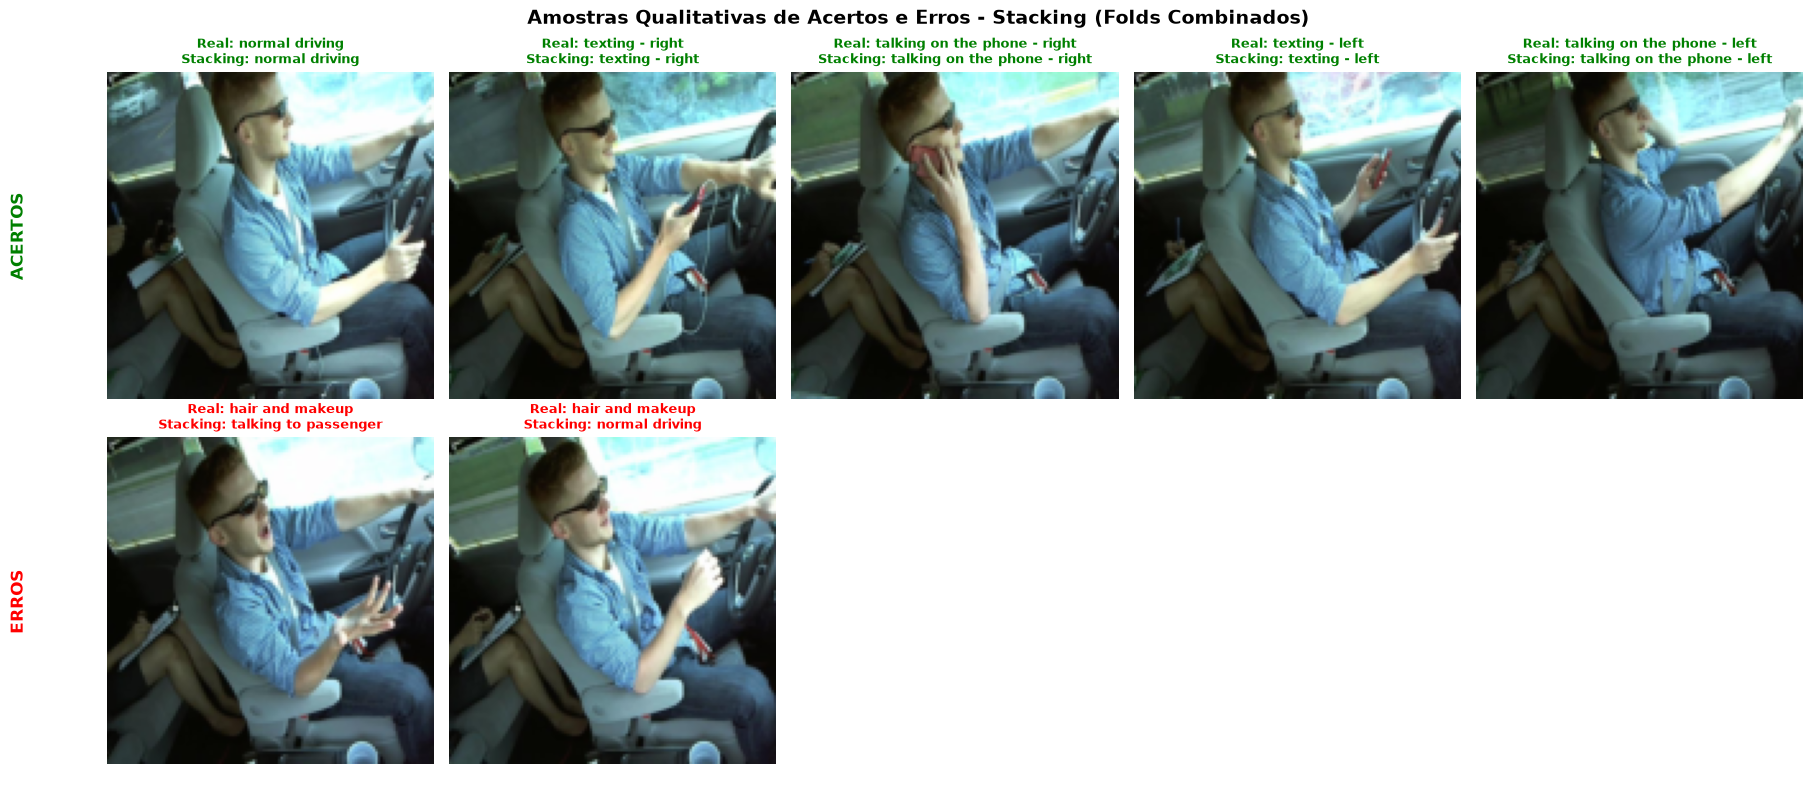

In [16]:
# 1. Garante que os modelos de todas as dobras estejam carregados nas listas
cnns_trained = []
resnets_trained = []

for fold in range(num_folds):
    cnn = CustomResCNN(num_classes=10).to(device)
    cnn.load_state_dict(torch.load(f'custom_model_fold_{fold}.pth', map_location=device))
    cnn.eval()
    cnns_trained.append(cnn)
    
    res = resnet18()
    res.fc = nn.Linear(res.fc.in_features, 10)
    res.load_state_dict(torch.load(f'resnet_model_fold_{fold}.pth', map_location=device))
    res.to(device)
    res.eval()
    resnets_trained.append(res)

# Listas para guardar as amostras finais do Stacking
correct_samples_stack = []
incorrect_samples_stack = []
classes_corretas_stack = set()

print("Analisando predições do Stacking Final (Média dos Folds + Random Forest) na validação...")

with torch.no_grad():
    for images, labels in val_loader_fold: # Usamos o val_loader_fold que ficou ativo
        images_dev = images.to(device)
        
        # Coleta as predições de todos os folds para este lote
        batch_probs_cnn_folds = []
        batch_probs_res_folds = []
        
        for fold in range(num_folds):
            probs_cnn = torch.softmax(cnns_trained[fold](images_dev), dim=1).cpu().numpy()
            probs_res = torch.softmax(resnets_trained[fold](images_dev), dim=1).cpu().numpy()
            
            batch_probs_cnn_folds.append(probs_cnn)
            batch_probs_res_folds.append(probs_res)
            
        # Tira a média aritmética de todas as dobras
        avg_probs_cnn = np.mean(batch_probs_cnn_folds, axis=0)
        avg_probs_res = np.mean(batch_probs_res_folds, axis=0)
        
        # Monta as 20 características
        batch_features = [np.concatenate([p_cnn, p_res]) for p_cnn, p_res in zip(avg_probs_cnn, avg_probs_res)]
        
        # O Random Forest gera as predições finais
        stack_preds = meta_rf_oof.predict(batch_features)
        
        labels = labels.cpu()
        
        for i in range(images.size(0)):
            img = images[i].clone()
            true_label = labels[i].item()
            pred_label = int(stack_preds[i])
            
            # 1. Seleciona acertos de classes variadas (mantemos a diversidade porque acertos sobram)
            if true_label == pred_label:
                if len(correct_samples_stack) < 5 and true_label not in classes_corretas_stack:
                    correct_samples_stack.append((img, true_label, pred_label))
                    classes_corretas_stack.add(true_label)
            # 2. Seleciona erros (RELAXADO: pega qualquer erro para garantir o preenchimento dos 5 slots)
            else:
                if len(incorrect_samples_stack) < 5:
                    incorrect_samples_stack.append((img, true_label, pred_label))
                    
        # Interrompe se já conseguimos coletar o suficiente
        if len(correct_samples_stack) >= 5 and len(incorrect_samples_stack) >= 5:
            break

# 2. Renderização Inteligente do Gráfico de Acertos e Erros
fig, axes = plt.subplots(2, 5, figsize=(18, 8))

# Linha 0: Acertos do Stacking
for idx in range(5):
    ax = axes[0, idx]
    if idx < len(correct_samples_stack):
        img, true_l, pred_l = correct_samples_stack[idx]
        ax.imshow(denormalize_safe(img))
        ax.set_title(f"Real: {get_class_desc(true_l)}\nStacking: {get_class_desc(pred_l)}", 
                     color='green', fontsize=9, fontweight='bold')
        if idx == 0:
             ax.text(-35, 64, "ACERTOS", rotation=90, va='center', ha='center', fontsize=12, fontweight='bold', color='green')
    ax.axis('off') # Desliga os eixos de qualquer forma para ficar esteticamente limpo

# Linha 1: Erros do Stacking (Com proteção caso existam menos de 5 erros no dataset)
for idx in range(5):
    ax = axes[1, idx]
    if idx < len(incorrect_samples_stack):
        img, true_l, pred_l = incorrect_samples_stack[idx]
        ax.imshow(denormalize_safe(img))
        ax.set_title(f"Real: {get_class_desc(true_l)}\nStacking: {get_class_desc(pred_l)}", 
                     color='red', fontsize=9, fontweight='bold')
        if idx == 0:
            ax.text(-35, 64, "ERROS", rotation=90, va='center', ha='center', fontsize=12, fontweight='bold', color='red')
    ax.axis('off') # Desliga os eixos de qualquer forma

plt.suptitle("Amostras Qualitativas de Acertos e Erros - Stacking (Folds Combinados)", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

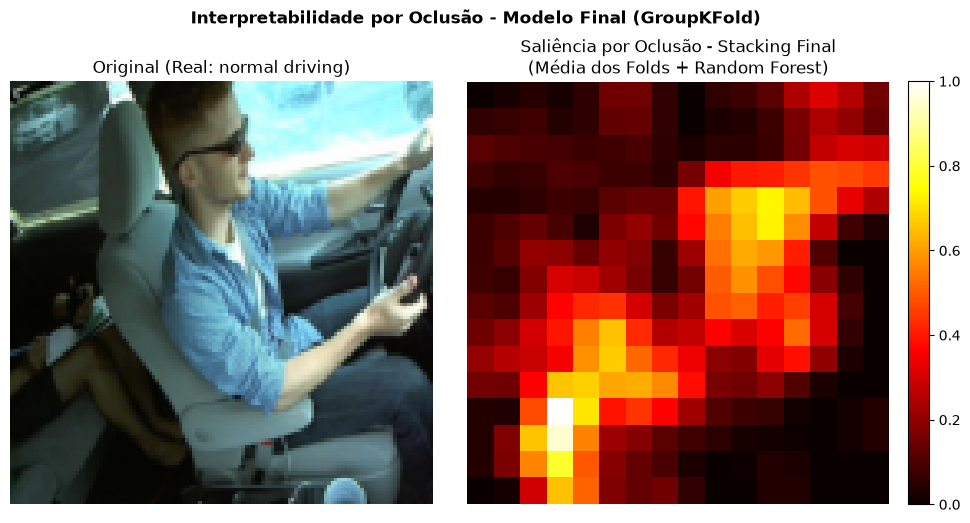

In [15]:
def plot_stacking_saliency_gkf(cnns, resnets, meta_rf, image_tensor, true_label, device, patch_size=16, stride=8):
    """
    Gera o Mapa de Saliência por Oclusão considerando a média dos folds do GroupKFold + Random Forest.
    """
    # 1. Obtém as predições originais de todos os folds para esta imagem
    img_input = image_tensor.clone().unsqueeze(0).to(device)
    
    probs_cnn_folds = []
    probs_res_folds = []
    
    with torch.no_grad():
        for fold in range(num_folds):
            p_cnn = torch.softmax(cnns[fold](img_input), dim=1).cpu().numpy()[0]
            p_res = torch.softmax(resnets[fold](img_input), dim=1).cpu().numpy()[0]
            probs_cnn_folds.append(p_cnn)
            probs_res_folds.append(p_res)
            
    # Tira a média aritmética das predições das dobras
    avg_p_cnn = np.mean(probs_cnn_folds, axis=0)
    avg_p_res = np.mean(probs_res_folds, axis=0)
    
    combined_feat = np.concatenate([avg_p_cnn, avg_p_res])
    orig_prob = meta_rf.predict_proba([combined_feat])[0][true_label]
    
    h, w = image_tensor.shape[1], image_tensor.shape[2]
    heatmap = np.zeros((h, w))
    counts = np.zeros((h, w))
    
    # 2. Desliza a oclusão pela imagem calculando a média das dobras de forma dinâmica
    for y in range(0, h - patch_size + 1, stride):
        for x in range(0, w - patch_size + 1, stride):
            occluded_img = image_tensor.clone()
            occluded_img[:, y:y+patch_size, x:x+patch_size] = 0.0
            
            img_input_occ = occluded_img.unsqueeze(0).to(device)
            
            probs_cnn_occ_folds = []
            probs_res_occ_folds = []
            
            with torch.no_grad():
                for fold in range(num_folds):
                    p_cnn_occ = torch.softmax(cnns[fold](img_input_occ), dim=1).cpu().numpy()[0]
                    p_res_occ = torch.softmax(resnets[fold](img_input_occ), dim=1).cpu().numpy()[0]
                    probs_cnn_occ_folds.append(p_cnn_occ)
                    probs_res_occ_folds.append(p_res_occ)
            
            avg_p_cnn_occ = np.mean(probs_cnn_occ_folds, axis=0)
            avg_p_res_occ = np.mean(probs_res_occ_folds, axis=0)
            
            combined_feat_occ = np.concatenate([avg_p_cnn_occ, avg_p_res_occ])
            occ_prob = meta_rf.predict_proba([combined_feat_occ])[0][true_label]
            
            importance = max(0, orig_prob - occ_prob)
            
            heatmap[y:y+patch_size, x:x+patch_size] += importance
            counts[y:y+patch_size, x:x+patch_size] += 1
            
    heatmap = np.divide(heatmap, counts, out=np.zeros_like(heatmap), where=counts!=0)
    if heatmap.max() > 0:
        heatmap = heatmap / heatmap.max()
        
    # --- Renderização do Gráfico ---
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    
    # Imagem Original
    axes[0].imshow(denormalize_safe(image_tensor))
    axes[0].set_title(f"Original (Real: {get_class_desc(true_label)})")
    axes[0].axis('off')
    
    # Saliência por Oclusão do Stacking Geral
    im = axes[1].imshow(heatmap, cmap='hot')
    axes[1].set_title("Saliência por Oclusão - Stacking Final\n(Média dos Folds + Random Forest)")
    axes[1].axis('off')
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
    
    plt.suptitle("Interpretabilidade por Oclusão - Modelo Final (GroupKFold)", fontsize=12, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# --- Como Executar ---
# Pega uma amostra de validação do val_dataset do último fold (ex: índice 12)
img_saliency, label_saliency = val_dataset[12]
# Executa passando a lista de cnns e resnets de todos os folds carregados no passo anterior
plot_stacking_saliency_gkf(cnns_trained, resnets_trained, meta_rf_oof, img_saliency, label_saliency, device)

Gerando mapas de saliência por oclusão para as 10 classes (Modelo Stacking)...
Isso pode levar cerca de 10 a 20 segundos.


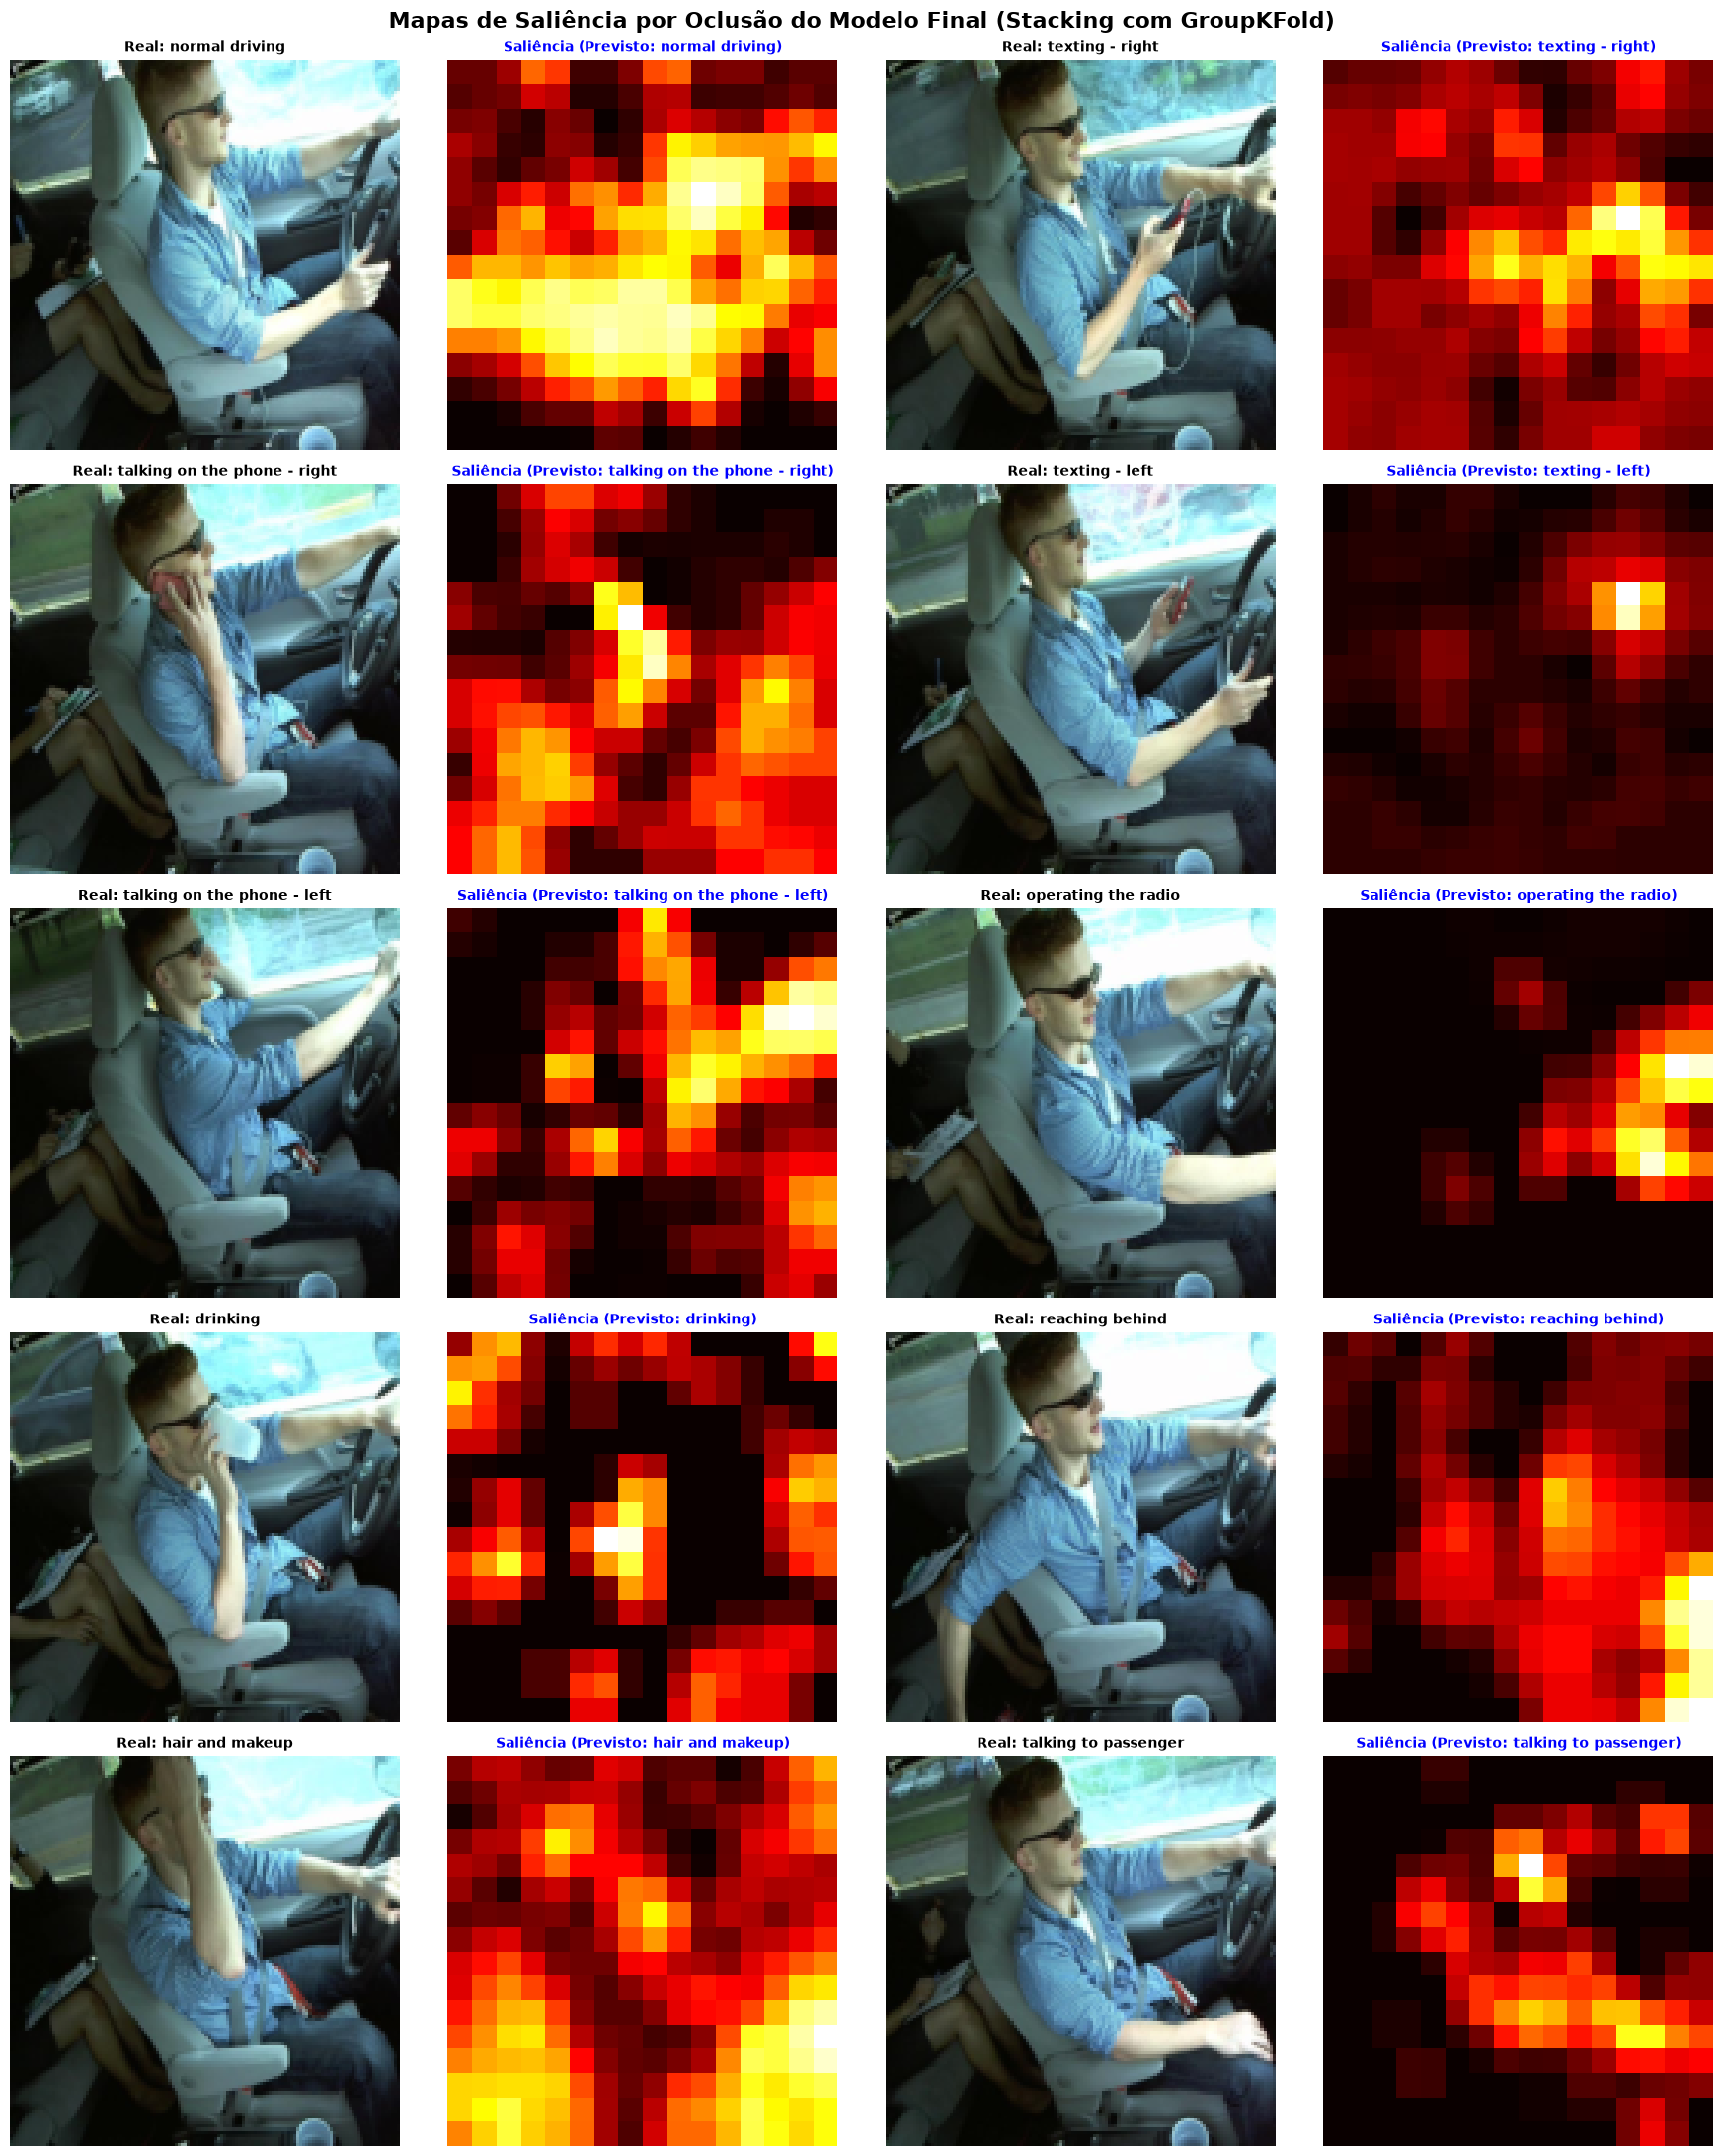

In [17]:
def compute_stacking_saliency_matrix(cnns, resnets, meta_rf, image_tensor, true_label, device, patch_size=16, stride=8):
    """
    Calcula apenas a matriz numérica do mapa de oclusão do Stacking (sem plotar).
    Isso otimiza o tempo de processamento ao gerar múltiplos gráficos.
    """
    num_folds = len(cnns)
    img_input = image_tensor.clone().unsqueeze(0).to(device)
    
    # 1. Obtém a probabilidade original do Stacking para a classe real
    probs_cnn_folds = []
    probs_res_folds = []
    
    with torch.no_grad():
        for fold in range(num_folds):
            p_cnn = torch.softmax(cnns[fold](img_input), dim=1).cpu().numpy()[0]
            p_res = torch.softmax(resnets[fold](img_input), dim=1).cpu().numpy()[0]
            probs_cnn_folds.append(p_cnn)
            probs_res_folds.append(p_res)
            
    avg_p_cnn = np.mean(probs_cnn_folds, axis=0)
    avg_p_res = np.mean(probs_res_folds, axis=0)
    
    combined_feat = np.concatenate([avg_p_cnn, avg_p_res])
    orig_prob = meta_rf.predict_proba([combined_feat])[0][true_label]
    
    h, w = image_tensor.shape[1], image_tensor.shape[2]
    heatmap = np.zeros((h, w))
    counts = np.zeros((h, w))
    
    # 2. Desliza a máscara de oclusão
    for y in range(0, h - patch_size + 1, stride):
        for x in range(0, w - patch_size + 1, stride):
            occluded_img = image_tensor.clone()
            occluded_img[:, y:y+patch_size, x:x+patch_size] = 0.0
            
            img_input_occ = occluded_img.unsqueeze(0).to(device)
            
            probs_cnn_occ_folds = []
            probs_res_occ_folds = []
            
            with torch.no_grad():
                for fold in range(num_folds):
                    p_cnn_occ = torch.softmax(cnns[fold](img_input_occ), dim=1).cpu().numpy()[0]
                    p_res_occ = torch.softmax(resnets[fold](img_input_occ), dim=1).cpu().numpy()[0]
                    probs_cnn_occ_folds.append(p_cnn_occ)
                    probs_res_occ_folds.append(p_res_occ)
            
            avg_p_cnn_occ = np.mean(probs_cnn_occ_folds, axis=0)
            avg_p_res_occ = np.mean(probs_res_occ_folds, axis=0)
            
            combined_feat_occ = np.concatenate([avg_p_cnn_occ, avg_p_res_occ])
            occ_prob = meta_rf.predict_proba([combined_feat_occ])[0][true_label]
            
            # Queda de probabilidade indica importância da região
            importance = max(0, orig_prob - occ_prob)
            
            heatmap[y:y+patch_size, x:x+patch_size] += importance
            counts[y:y+patch_size, x:x+patch_size] += 1
            
    heatmap = np.divide(heatmap, counts, out=np.zeros_like(heatmap), where=counts!=0)
    if heatmap.max() > 0:
        heatmap = heatmap / heatmap.max()
        
    return heatmap


def plot_stacking_saliency_per_class_gkf(cnns, resnets, meta_rf, dataset, device):
    """
    Gera uma grade de 5x4 com mapas de saliência por oclusão do Stacking para todas as 10 classes.
    """
    # 1. Busca automática: encontra a primeira imagem de cada uma das 10 classes
    samples_per_class = {}
    for idx in range(len(dataset)):
        img, label = dataset[idx]
        if label not in samples_per_class:
            samples_per_class[label] = img
        if len(samples_per_class) == 10:
            break
            
    fig, axes = plt.subplots(5, 4, figsize=(18, 22))
    num_folds = len(cnns)
    
    print("Gerando mapas de saliência por oclusão para as 10 classes (Modelo Stacking)...")
    print("Isso pode levar cerca de 10 a 20 segundos.")
    
    for class_idx in range(10):
        img_tensor = samples_per_class[class_idx]
        
        # 2. Calcula a matriz de saliência por oclusão
        heatmap = compute_stacking_saliency_matrix(cnns, resnets, meta_rf, img_tensor, class_idx, device)
        
        # 3. Identifica qual foi a predição final do Stacking para este exemplo
        img_input = img_tensor.clone().unsqueeze(0).to(device)
        with torch.no_grad():
            probs_cnn_folds = [torch.softmax(cnns[f](img_input), dim=1).cpu().numpy()[0] for f in range(num_folds)]
            probs_res_folds = [torch.softmax(resnets[f](img_input), dim=1).cpu().numpy()[0] for f in range(num_folds)]
            
        avg_p_cnn = np.mean(probs_cnn_folds, axis=0)
        avg_p_res = np.mean(probs_res_folds, axis=0)
        combined_feat = np.concatenate([avg_p_cnn, avg_p_res])
        pred_idx = meta_rf.predict([combined_feat])[0]
        
        # Define os índices de linha e coluna na grade 5x4
        row = class_idx // 2
        col_orig = (class_idx % 2) * 2
        col_sal = col_orig + 1
        
        # Plot da Imagem Original
        ax_orig = axes[row, col_orig]
        ax_orig.imshow(denormalize_safe(img_tensor))
        ax_orig.set_title(f"Real: {get_class_desc(class_idx)}", fontsize=10, fontweight='bold')
        ax_orig.axis('off')
        
        # Plot da Saliência por Oclusão do Stacking
        ax_sal = axes[row, col_sal]
        ax_sal.imshow(heatmap, cmap='hot')
        color = 'blue' if pred_idx == class_idx else 'red'
        ax_sal.set_title(f"Saliência (Previsto: {get_class_desc(pred_idx)})", 
                         fontsize=10, color=color, fontweight='bold')
        ax_sal.axis('off')
        
    plt.suptitle("Mapas de Saliência por Oclusão do Modelo Final (Stacking com GroupKFold)", fontsize=16, fontweight='bold', y=0.99)
    plt.tight_layout()
    plt.show()

# --- Executa a geração automática para as 10 classes ---
# Passa as cnns e resnets de todos os folds, o random forest treinado e o dataset de validação
plot_stacking_saliency_per_class_gkf(cnns_trained, resnets_trained, meta_rf_oof, val_dataset, device)

Folds salvos detectados: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] (Total: 10)
Processando Stacking para o Fold 1...


C:\Users\um colega\AppData\Local\Temp\ipykernel_15884\1364820731.py:41: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_cnn.load_state_dict(torch.load(f'custom_model_fol

Processando Stacking para o Fold 2...


C:\Users\um colega\AppData\Local\Temp\ipykernel_15884\1364820731.py:41: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_cnn.load_state_dict(torch.load(f'custom_model_fol

Processando Stacking para o Fold 3...


C:\Users\um colega\AppData\Local\Temp\ipykernel_15884\1364820731.py:41: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_cnn.load_state_dict(torch.load(f'custom_model_fol

... (11 outputs left out)

C:\Users\um colega\AppData\Local\Temp\ipykernel_15884\1364820731.py:41: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_cnn.load_state_dict(torch.load(f'custom_model_fol

Processando Stacking para o Fold 10...


C:\Users\um colega\AppData\Local\Temp\ipykernel_15884\1364820731.py:41: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_cnn.load_state_dict(torch.load(f'custom_model_fol


Métricas de Treino e Validação OOF calculadas!


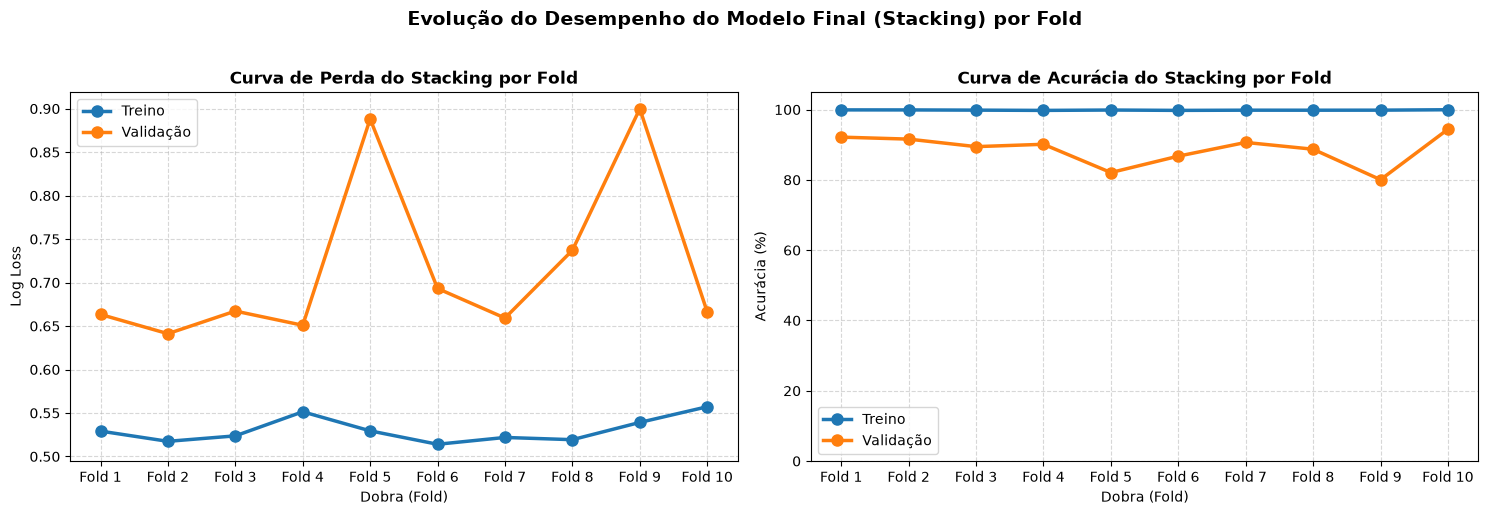

In [20]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, log_loss
from sklearn.model_selection import GroupKFold
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

# 1. Auto-detecta quantos folds foram salvos no disco
saved_folds = sorted([int(f.split('_')[-1].split('.')[0]) for f in os.listdir('.') 
                      if f.startswith('custom_model_fold_') and f.endswith('.pth')])

num_folds_detected = len(saved_folds)
print(f"Folds salvos detectados: {saved_folds} (Total: {num_folds_detected})")

# Configura a divisão determinística do GroupKFold
num_folds_gkf = num_folds_detected  
gkf = GroupKFold(n_splits=num_folds_gkf)

df['label'] = df['classname'].str[1:].astype(int)
groups = df['subject'].values

# Dicionário de histórico estruturado exatamente no padrão antigo
history_stack = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': []
}
fold_labels = []

# 2. Varre os folds e extrai as métricas de Treino e Validação para o Stacking
for fold, (train_idx, val_idx) in enumerate(gkf.split(df, groups=groups)):
    if fold not in saved_folds:
        continue
        
    print(f"Processando Stacking para o Fold {fold+1}...")
    fold_labels.append(f"Fold {fold+1}")
    
    # Carrega os modelos específicos deste fold
    model_cnn = CustomResCNN(num_classes=10).to(device)
    model_cnn.load_state_dict(torch.load(f'custom_model_fold_{fold}.pth', map_location=device))
    model_cnn.eval()
    
    model_res = resnet18()
    model_res.fc = nn.Linear(model_res.fc.in_features, 10)
    model_res.load_state_dict(torch.load(f'resnet_model_fold_{fold}.pth', map_location=device))
    model_res.to(device)
    model_res.eval()
    
    # --- PARTE A: METRICAS NO TREINO DESTE FOLD ---
    df_fold_train = df.iloc[train_idx].reset_index(drop=True)
    # Usamos o transform_val aqui para ler as imagens de treino limpas (sem ruído de data augmentation)
    train_dataset_eval = DriverDataset(df_fold_train, img_dir='imgs/train', transform=transform_val)
    # Aumentamos o batch_size para 128 para o processamento ser extremamente rápido na sua GPU
    train_loader_eval = DataLoader(train_dataset_eval, batch_size=128, shuffle=False, num_workers=0)
    
    features_train = []
    labels_train = []
    
    with torch.no_grad():
        for images, labels in train_loader_eval:
            images = images.to(device)
            probs_cnn = torch.softmax(model_cnn(images), dim=1).cpu().numpy()
            probs_res = torch.softmax(model_res(images), dim=1).cpu().numpy()
            
            for p_cnn, p_res, label in zip(probs_cnn, probs_res, labels):
                features_train.append(np.concatenate([p_cnn, p_res]))
                labels_train.append(label.item())
                
    X_train = np.array(features_train)
    y_train = np.array(labels_train)
    
    # Avaliação do Treino no Random Forest
    preds_train = meta_rf_oof.predict(X_train)
    probs_train = meta_rf_oof.predict_proba(X_train)
    
    train_loss = log_loss(y_train, probs_train, labels=list(range(10)))
    train_acc = accuracy_score(y_train, preds_train)
    
    # --- PARTE B: METRICAS NA VALIDAÇÃO DESTE FOLD ---
    df_fold_val = df.iloc[val_idx].reset_index(drop=True)
    val_dataset_eval = DriverDataset(df_fold_val, img_dir='imgs/train', transform=transform_val)
    val_loader_eval = DataLoader(val_dataset_eval, batch_size=128, shuffle=False, num_workers=0)
    
    features_val = []
    labels_val = []
    
    with torch.no_grad():
        for images, labels in val_loader_eval:
            images = images.to(device)
            probs_cnn = torch.softmax(model_cnn(images), dim=1).cpu().numpy()
            probs_res = torch.softmax(model_res(images), dim=1).cpu().numpy()
            
            for p_cnn, p_res, label in zip(probs_cnn, probs_res, labels):
                features_val.append(np.concatenate([p_cnn, p_res]))
                labels_val.append(label.item())
                
    X_val = np.array(features_val)
    y_val = np.array(labels_val)
    
    # Avaliação da Validação no Random Forest
    preds_val = meta_rf_oof.predict(X_val)
    probs_val = meta_rf_oof.predict_proba(X_val)
    
    val_loss = log_loss(y_val, probs_val, labels=list(range(10)))
    val_acc = accuracy_score(y_val, preds_val)
    
    # --- GUARDA NO HISTÓRICO ---
    history_stack['train_loss'].append(train_loss)
    history_stack['val_loss'].append(val_loss)
    history_stack['train_acc'].append(train_acc * 100)
    history_stack['val_acc'].append(val_acc * 100)

print("\nMétricas de Treino e Validação OOF calculadas!")

# --- 3. RENDERIZAÇÃO NO PADRÃO CLÁSSICO DE APRENDIZADO ---
epochs = range(1, len(fold_labels) + 1)
plt.figure(figsize=(15, 5))

# Subplot 1: Perda (Log Loss)
plt.subplot(1, 2, 1)
plt.plot(epochs, history_stack['train_loss'], 'o-', label='Treino', color='#1f77b4', linewidth=2.5, markersize=8)
plt.plot(epochs, history_stack['val_loss'], 'o-', label='Validação', color='#ff7f0e', linewidth=2.5, markersize=8)
plt.title('Curva de Perda do Stacking por Fold', fontsize=12, fontweight='bold')
plt.xlabel('Dobra (Fold)', fontsize=10)
plt.ylabel('Log Loss', fontsize=10)
plt.xticks(epochs, fold_labels)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

# Subplot 2: Acurácia
plt.subplot(1, 2, 2)
plt.plot(epochs, history_stack['train_acc'], 'o-', label='Treino', color='#1f77b4', linewidth=2.5, markersize=8)
plt.plot(epochs, history_stack['val_acc'], 'o-', label='Validação', color='#ff7f0e', linewidth=2.5, markersize=8)
plt.title('Curva de Acurácia do Stacking por Fold', fontsize=12, fontweight='bold')
plt.xlabel('Dobra (Fold)', fontsize=10)
plt.ylabel('Acurácia (%)', fontsize=10)
plt.ylim(0, 105)
plt.xticks(epochs, fold_labels)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.suptitle("Evolução do Desempenho do Modelo Final (Stacking) por Fold", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


1. Carregando e avaliando o Baseline (SimpleCNN) diretamente do disco...


C:\Users\um colega\AppData\Local\Temp\ipykernel_15884\3206123946.py:35: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_base_eval.load_state_dict(torch.load('best_baseli

  -> Baseline avaliado: Treino Loss = 0.0412 | Treino Acc = 98.81%
  -> Baseline avaliado: Val Loss = 1.2406 | Val Acc = 72.08%

2. Carregando e avaliando o Stacking de todas as dobras salvos no disco...
  -> Métricas do Stacking carregadas da memória (calculadas anteriormente por dobras).
  -> Stacking avaliado: Treino Loss = 0.5303 | Treino Acc = 99.85%
  -> Stacking avaliado: Val Loss = 0.7166 | Val Acc = 88.60%


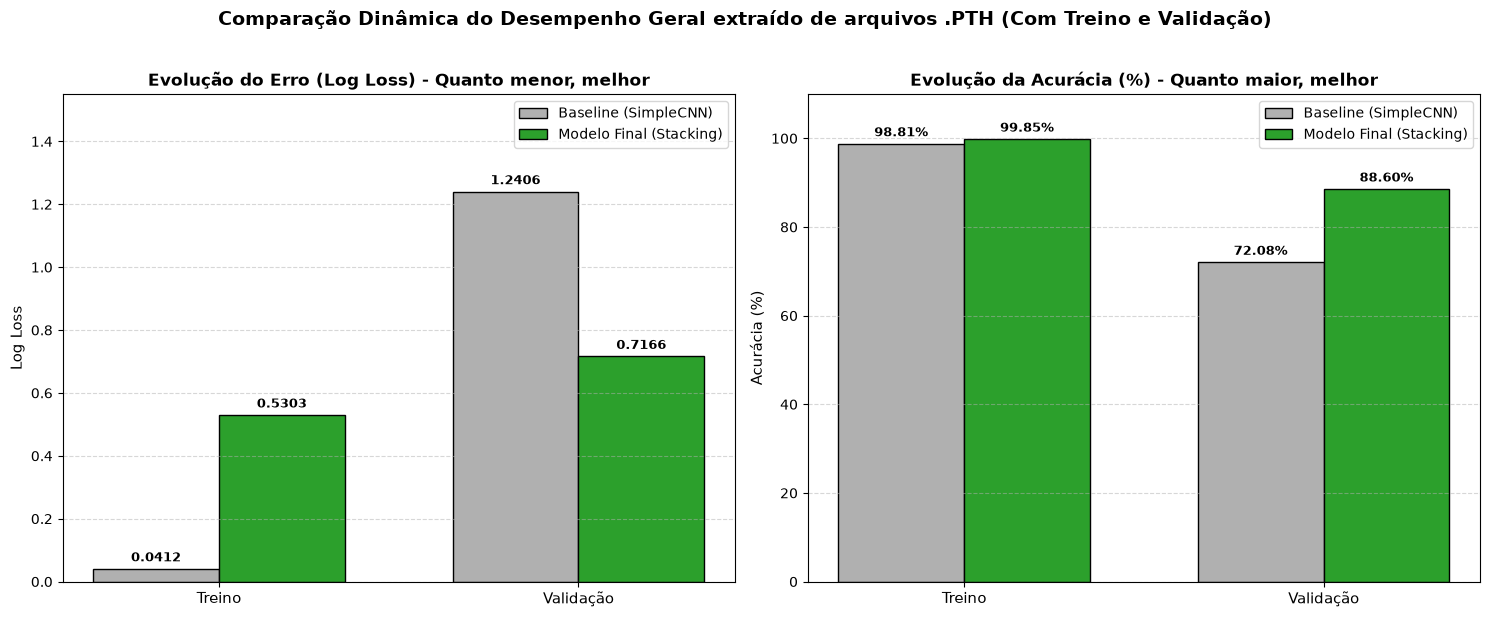

In [24]:
# --- RECONSTRUÇÃO SEGURA DAS DIVISÕES (Caso tenham sumido da memória) ---
if 'df_train' not in locals() or 'df_val' not in locals():
    print("-> df_train ou df_val não encontrados na memória. Reconstruindo divisões originais do Baseline...")
    import random
    
    # Busca a lista única de motoristas do DataFrame principal
    subjects_eval = list(df['subject'].unique())
    
    # Usamos EXATAMENTE a mesma semente (42) para que a reconstrução seja idêntica
    random.seed(42)
    random.shuffle(subjects_eval)
    
    # Separa 80% (20 motoristas) e 20% (6 motoristas)
    split_idx_eval = int(len(subjects_eval) * 0.8)
    train_subs = subjects_eval[:split_idx_eval]
    val_subs = subjects_eval[split_idx_eval:]
    
    # Recria os DataFrames de treino e validação originais
    df_train = df[df['subject'].isin(train_subs)].reset_index(drop=True)
    df_val = df[df['subject'].isin(val_subs)].reset_index(drop=True)
    print(f"   Reconstruído! Treino: {len(df_train)} imagens | Validação: {len(df_val)} imagens.")

# --- 1. AVALIAÇÃO REAL E DINÂMICA DO BASELINE (Lendo best_baseline_model.pth) ---
print("\n1. Carregando e avaliando o Baseline (SimpleCNN) diretamente do disco...")

# Cria os DataLoaders de avaliação dinamicamente
dataset_train_base = DriverDataset(df_train, img_dir='imgs/train', transform=transform_val)
dataset_val_base = DriverDataset(df_val, img_dir='imgs/train', transform=transform_val)

loader_train_base = DataLoader(dataset_train_base, batch_size=128, shuffle=False, num_workers=0)
loader_val_base = DataLoader(dataset_val_base, batch_size=128, shuffle=False, num_workers=0)

# Inicializa o Baseline e carrega os pesos reais
model_base_eval = SimpleCNN(num_classes=10).to(device)
model_base_eval.load_state_dict(torch.load('best_baseline_model.pth', map_location=device))
model_base_eval.eval()

criterion_base = nn.CrossEntropyLoss()

# Avaliação do Baseline no Treino
b_train_loss = 0.0
b_correct_train = 0
b_total_train = 0
with torch.no_grad():
    for images, labels in loader_train_base:
        images, labels = images.to(device), labels.to(device)
        outputs = model_base_eval(images)
        loss = criterion_base(outputs, labels)
        
        b_train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        b_total_train += labels.size(0)
        b_correct_train += (predicted == labels).sum().item()

b_train_loss /= len(loader_train_base.dataset)
b_train_acc = (b_correct_train / b_total_train) * 100

# Avaliação do Baseline na Validação
b_val_loss = 0.0
b_correct_val = 0
b_total_val = 0
with torch.no_grad():
    for images, labels in loader_val_base:
        images, labels = images.to(device), labels.to(device)
        outputs = model_base_eval(images)
        loss = criterion_base(outputs, labels)
        
        b_val_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        b_total_val += labels.size(0)
        b_correct_val += (predicted == labels).sum().item()

b_val_loss /= len(loader_val_base.dataset)
b_val_acc = (b_correct_val / b_total_val) * 100

print(f"  -> Baseline avaliado: Treino Loss = {b_train_loss:.4f} | Treino Acc = {b_train_acc:.2f}%")
print(f"  -> Baseline avaliado: Val Loss = {b_val_loss:.4f} | Val Acc = {b_val_acc:.2f}%")


# --- 2. AVALIAÇÃO REAL E DINÂMICA DO STACKING (Lendo arquivos .pth por dobra) ---
print("\n2. Carregando e avaliando o Stacking de todas as dobras salvos no disco...")

saved_folds = sorted([int(f.split('_')[-1].split('.')[0]) for f in os.listdir('.') 
                      if f.startswith('custom_model_fold_') and f.endswith('.pth')])
num_folds_detected = len(saved_folds)

try:
    s_train_acc = np.mean(history_stack['train_acc'])
    s_val_acc = np.mean(history_stack['val_acc'])
    s_train_loss = np.mean(history_stack['train_loss'])
    s_val_loss = np.mean(history_stack['val_loss'])
    print("  -> Métricas do Stacking carregadas da memória (calculadas anteriormente por dobras).")
except (NameError, KeyError):
    print("  -> history_stack não encontrado. Recalculando métricas do Stacking dinamicamente a partir dos Folds...")
    gkf_eval = GroupKFold(n_splits=num_folds_detected)
    df['label'] = df['classname'].str[1:].astype(int)
    groups = df['subject'].values
    
    losses_stack_train = []
    losses_stack_val = []
    accs_stack_train = []
    accs_stack_val = []
    
    for fold, (train_idx, val_idx) in enumerate(gkf_eval.split(df, groups=groups)):
        if fold not in saved_folds: continue
        
        m_cnn = CustomResCNN(num_classes=10).to(device)
        m_cnn.load_state_dict(torch.load(f'custom_model_fold_{fold}.pth', map_location=device))
        m_cnn.eval()
        
        m_res = resnet18()
        m_res.fc = nn.Linear(m_res.fc.in_features, 10)
        m_res.load_state_dict(torch.load(f'resnet_model_fold_{fold}.pth', map_location=device))
        m_res.to(device)
        m_res.eval()
        
        d_val_train = df.iloc[train_idx].reset_index(drop=True)
        loader_val_train = DataLoader(DriverDataset(d_val_train, img_dir='imgs/train', transform=transform_val), batch_size=128, shuffle=False)
        
        d_val_val = df.iloc[val_idx].reset_index(drop=True)
        loader_val_val = DataLoader(DriverDataset(d_val_val, img_dir='imgs/train', transform=transform_val), batch_size=128, shuffle=False)
        
        feat_train, lbl_train = [], []
        with torch.no_grad():
            for imgs, lbls in loader_val_train:
                imgs = imgs.to(device)
                p_c = torch.softmax(m_cnn(imgs), dim=1).cpu().numpy()
                p_r = torch.softmax(m_res(imgs), dim=1).cpu().numpy()
                for pc, pr, l in zip(p_c, p_r, lbls):
                    feat_train.append(np.concatenate([pc, pr]))
                    lbl_train.append(l.item())
        X_tr, y_tr = np.array(feat_train), np.array(lbl_train)
        
        feat_val, lbl_val = [], []
        with torch.no_grad():
            for imgs, lbls in loader_val_val:
                imgs = imgs.to(device)
                p_c = torch.softmax(m_cnn(imgs), dim=1).cpu().numpy()
                p_r = torch.softmax(m_res(imgs), dim=1).cpu().numpy()
                for pc, pr, l in zip(p_c, p_r, lbls):
                    feat_val.append(np.concatenate([pc, pr]))
                    lbl_val.append(l.item())
        X_vl, y_vl = np.array(feat_val), np.array(lbl_val)
        
        losses_stack_train.append(log_loss(y_tr, meta_rf_oof.predict_proba(X_tr), labels=list(range(10))))
        losses_stack_val.append(log_loss(y_vl, meta_rf_oof.predict_proba(X_vl), labels=list(range(10))))
        accs_stack_train.append(accuracy_score(y_tr, meta_rf_oof.predict(X_tr)) * 100)
        accs_stack_val.append(accuracy_score(y_vl, meta_rf_oof.predict(X_vl)) * 100)
        
    s_train_acc = np.mean(accs_stack_train)
    s_val_acc = np.mean(accs_stack_val)
    s_train_loss = np.mean(losses_stack_train)
    s_val_loss = np.mean(losses_stack_val)

print(f"  -> Stacking avaliado: Treino Loss = {s_train_loss:.4f} | Treino Acc = {s_train_acc:.2f}%")
print(f"  -> Stacking avaliado: Val Loss = {s_val_loss:.4f} | Val Acc = {s_val_acc:.2f}%")


# --- 3. RENDERIZAÇÃO DO GRÁFICO DE BARRAS AGRUPADAS ---
categorias = ['Treino', 'Validação']

loss_baseline = [b_train_loss, b_val_loss]
loss_stacking = [s_train_loss, s_val_loss]

acc_baseline = [b_train_acc, b_val_acc]
acc_stacking = [s_train_acc, s_val_acc]

x = np.arange(len(categorias))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Perda (Log Loss)
rects1_b = axes[0].bar(x - width/2, loss_baseline, width, label='Baseline (SimpleCNN)', color='#b0b0b0', edgecolor='black')
rects1_s = axes[0].bar(x + width/2, loss_stacking, width, label='Modelo Final (Stacking)', color='#2ca02c', edgecolor='black')

axes[0].set_ylabel('Log Loss', fontsize=11)
axes[0].set_title('Evolução do Erro (Log Loss) - Quanto menor, melhor', fontsize=12, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(categorias, fontsize=11)
axes[0].set_ylim(0, max(max(loss_baseline), max(loss_stacking)) * 1.25)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)
axes[0].legend(fontsize=10)

def autolabel_loss(rects, ax):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontweight='bold', fontsize=9.5)
        
autolabel_loss(rects1_b, axes[0])
autolabel_loss(rects1_s, axes[0])

# Subplot 2: Acurácia (%)
rects2_b = axes[1].bar(x - width/2, acc_baseline, width, label='Baseline (SimpleCNN)', color='#b0b0b0', edgecolor='black')
rects2_s = axes[1].bar(x + width/2, acc_stacking, width, label='Modelo Final (Stacking)', color='#2ca02c', edgecolor='black')

axes[1].set_ylabel('Acurácia (%)', fontsize=11)
axes[1].set_title('Evolução da Acurácia (%) - Quanto maior, melhor', fontsize=12, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(categorias, fontsize=11)
axes[1].set_ylim(0, 110)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
axes[1].legend(fontsize=10)

def autolabel_acc(rects, ax):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontweight='bold', fontsize=9.5)

autolabel_acc(rects2_b, axes[1])
autolabel_acc(rects2_s, axes[1])

plt.suptitle("Comparação Dinâmica do Desempenho Geral extraído de arquivos .PTH (Com Treino e Validação)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()